# Inside a Transformer: Every Step of an LLM, With the Maths and the Code

> **Who is this for:** learners who know roughly what an LLM is (a next-token predictor) and now want to see **every single step inside one**, with the maths written out in simple words and a small piece of code for each step.
>
> **What you will learn:** we build **one tiny decoder-only transformer** (the same family as GPT and Llama) piece by piece in **numpy**, then check it against a **PyTorch** version and train it on CPU in well under a minute:
> - **text to tokens** (a miniature BPE tokenizer, special tokens, vocabulary size trade-offs) and **tokens to vectors** (the embedding table as a matrix, tied input/output embeddings)
> - **positions**: sinusoidal, learned, **RoPE** (with a proof in code that it only cares about relative position), ALiBi, and how context windows are stretched (position interpolation, NTK, YaRN)
> - **self-attention from scratch**: Q, K, V, why we divide by $\sqrt{d_k}$, the causal mask, multi-head attention, MQA/GQA, cross-attention and the **online softmax** trick behind FlashAttention
> - **the block**: residual stream, LayerNorm and RMSNorm, the feed-forward network (GELU vs SwiGLU), dropout, **parameter counting** and where the FLOPs go
> - **the full forward pass**: logits, cross-entropy on shifted targets, perplexity, and a real training run
> - **generation**: the autoregressive loop, prefill vs decode, a **KV cache** built into the toy model, sampling (greedy, temperature, top-k, top-p, min-p), stop tokens, batching with padding masks
> - **training at scale** in simple words (Chinchilla, the $6ND$ rule, memory per parameter, parallelism, learning-rate schedules, loss spikes)
> - **after pre-training**: SFT with loss masking, LoRA maths, int8/int4 quantisation maths, RLHF and DPO formulas
> - **Mixture of Experts** and a **Mamba-style state-space recurrence** in miniature
> - **encoder-only vs decoder-only vs encoder-decoder**, and an **interpretability peek** (attention maps and the logit lens)
>
> **Prerequisites:** [Start Here: How LLMs Work](00_start_here_how_llms_work.ipynb) (next-token prediction, sampling, a tiny GPT), [Transformer Architecture](../05_Deep_Learning/05_transformers_architecture.ipynb), [Word Embeddings](../07_NLP/02_word_embeddings.ipynb). Basic numpy and matrix multiplication.
>
> **Time needed:** about 3 hours to read and play. The notebook itself runs in about 1-2 minutes on a laptop CPU.
>
> **Runs on:** CPU, no API key, no internet. Only numpy, matplotlib and PyTorch (CPU).

**How this notebook relates to the others.** Several notebooks already go deep on single topics. Here we keep one thread, "follow a sentence through the model", and link out for the deep dives:

| Topic | Deep dive elsewhere |
|---|---|
| A first tiny GPT and sampling, with a real small model | [00_start_here_how_llms_work](00_start_here_how_llms_work.ipynb) |
| The transformer diagram and a toy encoder-decoder | [05_transformers_architecture](../05_Deep_Learning/05_transformers_architecture.ipynb) |
| KV cache, prefix and prompt caching in depth | [23_llm_caching_kv_cache_prompt_semantic_cag](23_llm_caching_kv_cache_prompt_semantic_cag.ipynb) |
| MHA / GQA / MLA, decoding settings, quantisation, MoE as model "axes" | [24_how_llms_differ_from_each_other](24_how_llms_differ_from_each_other.ipynb) |
| FlashAttention, PagedAttention, speculative decoding, serving | [13_inference_optimization](13_inference_optimization.ipynb) |
| RoPE, ALiBi, MoE, Mamba, RMSNorm, SwiGLU (survey) | [14_llm_architecture_innovations](14_llm_architecture_innovations.ipynb) |
| RLHF, DPO and friends | [12_alignment_techniques](12_alignment_techniques.ipynb) |
| SFT, LoRA and DPO trained by hand on CPU | [21_fine_tuning_hands_on_cpu](21_fine_tuning_hands_on_cpu.ipynb) |

**The whole journey on one page** (we will build every box):

```mermaid
flowchart LR
    A["text"] --> B["tokenizer<br/>(BPE)"] --> C["token ids"] --> D["embedding<br/>lookup"]
    D --> E["+ position info"] --> F["N x transformer block<br/>(attention + FFN)"]
    F --> G["final norm"] --> H["unembedding<br/>(logits)"] --> I["softmax"] --> J["sample next token"]
    J -->|append and repeat| C
```

## 0. Setup

We import numpy (arrays and maths), matplotlib (plots) and PyTorch (only for the "check" and training steps). A fixed **random seed** (the starting number of the random generator) makes every run print the same numbers.

In [1]:
import math, re, time, random                       # standard-library helpers
from collections import Counter                     # counting things
import numpy as np                                  # arrays and maths
import matplotlib.pyplot as plt                     # plots
import torch                                        # PyTorch (CPU) for the check and training
import torch.nn as nn
import torch.nn.functional as F

SEED = 0
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
rng = np.random.default_rng(SEED)                   # our main numpy random generator
torch.set_num_threads(min(4, torch.get_num_threads()))
np.set_printoptions(precision=3, suppress=True)     # short, readable prints
NB_START = time.time()                              # to report total run time at the end

def softmax(z, axis=-1):
    """Turn scores into probabilities that add up to 1 along `axis`."""
    z = z - z.max(axis=axis, keepdims=True)         # subtract the max: same result, no overflow
    e = np.exp(z)
    return e / e.sum(axis=axis, keepdims=True)

print("numpy", np.__version__, "| torch", torch.__version__, "| threads", torch.get_num_threads())

numpy 2.5.4 | torch 2.15.0+cpu | threads 4


## 1. Text to tokens, and tokens to vectors

A neural network only understands numbers. So step one is to cut text into pieces called **tokens** and give each piece a whole number, its **token id**. Step two turns each id into a vector of real numbers, its **embedding**.

### 1.1 Our tiny training text

We need a small text that a tiny model can actually learn in a few seconds. We generate simple sentences from a fixed grammar ("the cat chases the ball in the garden."). This is toy data, not real language, but it has real structure: word order, agreement, sentence ends.

In [2]:
SUBJ  = ["the cat", "the dog", "a bird", "the old man", "my sister", "the teacher", "a small child"]
VERB  = ["sees", "likes", "finds", "chases", "holds", "wants"]
OBJ   = ["the ball", "a red apple", "the blue box", "a book", "the green hat", "some water"]
PLACE = ["in the garden", "at home", "near the river", "on the table", "under the tree"]
ADJ   = ["happy", "tired", "hungry", "very quiet", "sleepy"]
VERB2 = ["play", "sleep", "sit", "walk"]            # plural verbs for "X and Y ..."

def make_line(r):
    t = r.random()
    if t < 0.6:  return f"{r.choice(SUBJ)} {r.choice(VERB)} {r.choice(OBJ)} {r.choice(PLACE)}."
    if t < 0.85: return f"{r.choice(SUBJ)} is {r.choice(ADJ)}."
    return f"{r.choice(SUBJ)} and {r.choice(SUBJ)} {r.choice(VERB2)} {r.choice(PLACE)}."

r = random.Random(SEED)
lines = [make_line(r) for _ in range(1500)]
train_lines, val_lines = lines[:1350], lines[1350:]          # hold out 150 lines to measure honestly
corpus = "\n".join(train_lines)
print(len(lines), "lines,", len(corpus), "characters. Examples:")
for l in lines[:4]: print("  ", l)

1500 lines, 49653 characters. Examples:
   a small child is very quiet.
   my sister chases a book near the river.
   a bird and my sister sleep under the tree.
   the dog sees the green hat near the river.


### 1.2 Byte Pair Encoding (BPE) in miniature

**What it is.** BPE is the most common way to build a tokenizer. It starts from single characters and repeatedly **glues together the most frequent neighbouring pair** into a new token, until it has the vocabulary size you asked for.

**Simple analogy.** Like inventing shorthand while taking notes: if you write "the" a hundred times, you invent one squiggle for it.

**How it works (training):**
1. **Pre-tokenize**: split text into chunks (roughly words, with the leading space kept, like GPT-2: `" cat"`).
2. Write every chunk as a list of characters.
3. Count every adjacent pair across the corpus (weighted by how often each chunk appears).
4. Merge the most frequent pair everywhere, record it as merge rule number $k$.
5. Repeat steps 3-4 for the number of merges you want.

**Encoding new text** applies the learned merges **in the same order** (lowest rank first). **Decoding** just concatenates the token strings.

Real tokenizers (GPT-2, Llama 3, Qwen) are **byte-level**: they start from the 256 possible bytes instead of characters, so any text, emoji or binary data can be encoded and there is never an "unknown" token. Ours is character-level to stay readable. Paper: Sennrich et al., "Neural Machine Translation of Rare Words with Subword Units".

In [3]:
PRETOK = re.compile(r" ?[a-z]+| ?[^a-z\s]+|\s+")         # words keep their leading space, like GPT-2

def merge_pair(symbols, pair):
    """Replace every occurrence of the adjacent pair (a, b) in `symbols` by the joined string a+b."""
    out, i = [], 0
    while i < len(symbols):
        if i < len(symbols) - 1 and (symbols[i], symbols[i + 1]) == pair:
            out.append(symbols[i] + symbols[i + 1]); i += 2
        else:
            out.append(symbols[i]); i += 1
    return out

def train_bpe(text, num_merges):
    chunk_counts = Counter(PRETOK.findall(text))          # how often each word-chunk appears
    words = {c: list(c) for c in chunk_counts}            # each chunk as a list of characters
    merges = []
    for _ in range(num_merges):
        pairs = Counter()
        for c, n in chunk_counts.items():                 # count adjacent pairs, weighted by frequency
            s = words[c]
            for a, b in zip(s, s[1:]):
                pairs[(a, b)] += n
        if not pairs:                                     # every chunk is already one token
            break
        best = max(pairs, key=pairs.get)                  # most frequent pair
        merges.append(best)
        for c in words:
            words[c] = merge_pair(words[c], best)
    return merges

merges = train_bpe(corpus, 200)
print("learned", len(merges), "merges. The first 12 (most frequent first):")
print([a + b for a, b in merges[:12]])

learned 145 merges. The first 12 (most frequent first):
['he', 'the', ' the', ' s', ' a', 'er', ' b', ' t', 'ee', ' h', 'nd', 'ld']


Now the full tokenizer: a vocabulary of **special tokens** + single characters + merged tokens, an `encode` and a `decode`.

**Special tokens** are reserved ids that never come from normal text:

| Token | Meaning |
|---|---|
| `<pad>` | filler to make sequences in a batch the same length (ignored by attention and loss) |
| `<bos>` | "beginning of sequence": a fixed starting point for every text |
| `<eos>` | "end of sequence": the model learns to emit it, and generation stops when it does |
| `<unk>` | unknown character (byte-level tokenizers do not need this) |

Chat models add more, such as `<|user|>` and `<|assistant|>` markers (see section 8).

In [4]:
class TinyBPE:
    SPECIALS = ["<pad>", "<bos>", "<eos>", "<unk>"]

    def __init__(self, text, num_merges):
        self.merges = train_bpe(text, num_merges)
        self.rank = {pair: i for i, pair in enumerate(self.merges)}     # merge priority
        chars = sorted(set(text))
        tokens = self.SPECIALS + chars + [a + b for a, b in self.merges]
        self.itos = list(dict.fromkeys(tokens))                         # id -> string (no duplicates)
        self.stoi = {s: i for i, s in enumerate(self.itos)}             # string -> id
        self.cache = {}

    def _encode_chunk(self, chunk):
        if chunk in self.cache: return self.cache[chunk]
        s = list(chunk)
        while len(s) > 1:
            pairs = [(self.rank.get((a, b), 10**9), i) for i, (a, b) in enumerate(zip(s, s[1:]))]
            best_rank, i = min(pairs)
            if best_rank == 10**9: break                                # no learned merge applies
            s = merge_pair(s, (s[i], s[i + 1]))
        self.cache[chunk] = s
        return s

    def encode(self, text, bos=False, eos=False):
        ids = [self.stoi["<bos>"]] if bos else []
        for chunk in PRETOK.findall(text):
            ids += [self.stoi.get(t, self.stoi["<unk>"]) for t in self._encode_chunk(chunk)]
        return ids + ([self.stoi["<eos>"]] if eos else [])

    def decode(self, ids):
        return "".join(self.itos[i] for i in ids if self.itos[i] not in ("<pad>", "<bos>"))

tok = TinyBPE(corpus, 200)
PAD, BOS, EOS = tok.stoi["<pad>"], tok.stoi["<bos>"], tok.stoi["<eos>"]
V = len(tok.itos)
ids = tok.encode("the old man chases a red apple near the river.", bos=True, eos=True)
print("vocabulary size V =", V)
print("ids   :", ids)
print("tokens:", [tok.itos[i] for i in ids])
print("decode:", repr(tok.decode(ids)))
print("unseen word 'zebra' ->", [tok.itos[i] for i in tok.encode("the zebra")])

vocabulary size V = 176
ids   : [1, 32, 70, 72, 136, 35, 137, 139, 105, 33, 107, 6, 2]
tokens: ['<bos>', 'the', ' old', ' man', ' chases', ' a', ' red', ' apple', ' near', ' the', ' river', '.', '<eos>']
decode: 'the old man chases a red apple near the river.<eos>'
unseen word 'zebra' -> ['the', ' ', '<unk>', 'e', 'b', 'r', 'a']


Notice that the unseen word "zebra" still encodes: it just falls back to smaller pieces (some letters are not in our tiny corpus at all, so they become `<unk>`; a byte-level tokenizer would use bytes instead).

**Vocabulary size trade-off.** More merges means bigger tokens, so each text becomes **fewer tokens** (shorter sequences, cheaper attention, more text fits in the context window), but the embedding and output tables grow (cost $V \cdot d$ parameters each) and rare tokens get few training examples. Let us measure the compression on our corpus:

In [5]:
print(f"{'merges':>7} {'vocab':>6} {'tokens for val text':>20} {'chars per token':>16}")
val_text = "\n".join(val_lines)
for n in [0, 10, 30, 60, 100, 200]:
    t = TinyBPE(corpus, n)
    n_tok = len(t.encode(val_text))
    print(f"{n:>7} {len(t.itos):>6} {n_tok:>20} {len(val_text)/n_tok:>16.2f}")

 merges  vocab  tokens for val text  chars per token
      0     31                 5381             1.00
     10     41                 4220             1.28
     30     61                 3328             1.62
     60     91                 2604             2.07


    100    131                 1881             2.86
    200    176                 1429             3.77


| Vocabulary size | Pros | Cons | Typical use |
|---|---|---|---|
| small (a few thousand) | small embedding tables, every token well trained | long sequences, slower and costlier per text | character / byte models, tiny models |
| medium (32k-64k) | good balance for one main language | other languages and code split into many tokens | many earlier open models |
| large (100k-260k) | short sequences across many languages and code | big embedding and output layers, many rare tokens | most recent multilingual models (as of late 2026) |

More on how tokenizers differ between models: [24_how_llms_differ_from_each_other, section 3](24_how_llms_differ_from_each_other.ipynb) and [27_tokens_cost_batch_and_caching_llm_apis](27_tokens_cost_batch_and_caching_llm_apis.ipynb).

### 1.3 Token ids to embeddings: the lookup table is a matrix

**What it is.** The **embedding matrix** $E$ has one row per token: shape $V \times d_{model}$, where $d_{model}$ (written $d$ for short) is the width of the model, the length of every vector that flows through it.

**How it works.** Looking up row $i$ is exactly the same as multiplying a **one-hot vector** (all zeros except a 1 at position $i$) by $E$:

$$x = \text{onehot}(i)\,E = E[i,:]$$

So an embedding layer is just a linear layer with a very fast implementation (indexing instead of multiplying by mostly zeros). Its rows are learned by gradient descent like any other weight. Word2vec-style embeddings are covered in [07_NLP/02_word_embeddings](../07_NLP/02_word_embeddings.ipynb).

In [6]:
d_demo = 8
E = rng.normal(0, 0.02, size=(V, d_demo))          # embedding matrix, V rows x d columns
i = tok.stoi[" cat"]
onehot = np.zeros(V); onehot[i] = 1.0
print("E shape:", E.shape)
print("row lookup  E[i]       :", E[i])
print("one-hot @ E            :", onehot @ E)
print("identical?", np.allclose(E[i], onehot @ E))
batch_ids = np.array([[BOS, tok.stoi[" cat"], tok.stoi[" sees"]]])   # shape (B=1, T=3)
print("ids (B,T) =", batch_ids.shape, "-> embeddings (B,T,d) =", E[batch_ids].shape)

E shape: (176, 8)
row lookup  E[i]       : [-0.015  0.011  0.015  0.007 -0.047  0.02  -0.007 -0.024]
one-hot @ E            : [-0.015  0.011  0.015  0.007 -0.047  0.02  -0.007 -0.024]
identical? True
ids (B,T) = (1, 3) -> embeddings (B,T,d) = (1, 3, 8)


**Tied input and output embeddings.** At the very end, the model must turn its final vector $h$ (length $d$) back into one score per token (length $V$). That needs a $d \times V$ matrix, the **unembedding**. Many models simply reuse $E^\top$:

$$\text{logits} = h\,E^\top \qquad (\text{score for token } j = h \cdot E[j])$$

So a token's score is the dot product between the final hidden state and that token's own embedding. This **weight tying** saves $V \cdot d$ parameters (GPT-2 does it: $50257 \times 768 \approx 38.6$M saved). Large models often untie them because then those parameters are a small fraction of the total and separate matrices give a bit more freedom.

In [7]:
h = rng.normal(size=d_demo)                     # pretend final hidden state
logits = h @ E.T                                  # (d,) @ (d,V) -> (V,)
print("logits shape:", logits.shape, "| score of ' cat' equals h . E[cat]:", np.isclose(logits[i], h @ E[i]))
for name, Vx, dx in [("our toy", V, 64), ("GPT-2 small", 50257, 768), ("a 128k-vocab, d=4096 model", 128000, 4096)]:
    print(f"{name:>28}: tying saves V*d = {Vx*dx/1e6:8.2f} M parameters")

logits shape: (176,) | score of ' cat' equals h . E[cat]: True
                     our toy: tying saves V*d =     0.01 M parameters
                 GPT-2 small: tying saves V*d =    38.60 M parameters
  a 128k-vocab, d=4096 model: tying saves V*d =   524.29 M parameters


## 2. Positional information

**The problem.** Attention (section 3) compares every token with every other token using dot products. Nothing in that maths knows **where** a token sits. If you shuffle the input tokens, attention just shuffles its outputs the same way, so "dog bites man" and "man bites dog" would look identical. We must inject position. The tiny check below shows this "permutation equivariance".

In [8]:
def plain_attention(X):
    """Self-attention with Q=K=V=X and no mask (just to show the order problem)."""
    return softmax(X @ X.T / np.sqrt(X.shape[1])) @ X

X = rng.normal(size=(4, 8))                       # 4 tokens, no position information
perm = [2, 0, 3, 1]                               # shuffle the tokens
out, out_shuffled = plain_attention(X), plain_attention(X[perm])
print("shuffling the input just shuffles the output:", np.allclose(out[perm], out_shuffled))

shuffling the input just shuffles the output: True


### 2.1 Sinusoidal positions (the original transformer)

**What it is.** A fixed (not learned) vector for each position, added to the token embedding. Each pair of dimensions is a sine and cosine wave with a different speed:

$$PE(pos, 2i) = \sin\!\left(\frac{pos}{10000^{2i/d}}\right), \qquad PE(pos, 2i+1) = \cos\!\left(\frac{pos}{10000^{2i/d}}\right)$$

**Analogy.** A clock with many hands: the second hand (fast wave) tells nearby positions apart, the hour hand (slow wave) tells far-apart positions apart. Together they give every position a unique pattern.

**Nice property.** Moving by a fixed offset $k$ is a fixed rotation of each (sin, cos) pair, so the model can learn "look $k$ tokens back".

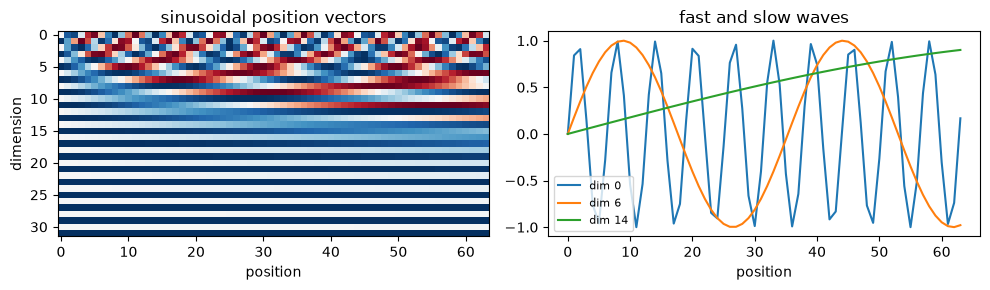

In [9]:
def sinusoidal_pe(T, d, base=10000.0):
    pos = np.arange(T)[:, None]                          # (T,1)
    i = np.arange(d // 2)[None, :]                        # (1,d/2)
    angle = pos / base ** (2 * i / d)                     # (T,d/2)
    pe = np.zeros((T, d))
    pe[:, 0::2], pe[:, 1::2] = np.sin(angle), np.cos(angle)
    return pe

pe = sinusoidal_pe(64, 32)
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].imshow(pe.T, aspect="auto", cmap="RdBu"); ax[0].set_xlabel("position"); ax[0].set_ylabel("dimension")
ax[0].set_title("sinusoidal position vectors")
for dim in [0, 6, 14]:
    ax[1].plot(pe[:, dim], label=f"dim {dim}")
ax[1].set_xlabel("position"); ax[1].set_title("fast and slow waves"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

### 2.2 Learned absolute positions

**What it is.** A second embedding table $P$ of shape $T_{max} \times d$; row $t$ is added to the token at position $t$: $x_t = E[\text{id}_t] + P[t]$. GPT-2 and BERT do this, and our toy model will too (it is the simplest).

**When to use / not.** Simple and works well inside the trained length, but it has **no row** for positions beyond $T_{max}$, so the model cannot run on longer text at all. That is one reason modern LLMs use RoPE.

### 2.3 RoPE: rotary position embedding

**What it is.** Instead of adding a position vector, RoPE **rotates** the query and key vectors by an angle that grows with position. Used by Llama, Qwen, Mistral and most open LLMs (as of late 2026).

**How it works.** Split a vector into pairs $(x_{2i}, x_{2i+1})$. Pair $i$ gets its own speed $\theta_i = \text{base}^{-2i/d}$ (base is usually 10000 or larger). At position $m$ we rotate the pair by angle $m\theta_i$:

$$\begin{pmatrix} x'_{2i} \\ x'_{2i+1} \end{pmatrix} = \begin{pmatrix} \cos m\theta_i & -\sin m\theta_i \\ \sin m\theta_i & \cos m\theta_i \end{pmatrix} \begin{pmatrix} x_{2i} \\ x_{2i+1} \end{pmatrix}$$

**Why it gives relative position.** Rotations have a neat rule: $R(a)^\top R(b) = R(b - a)$. So the attention score between a query at position $m$ and a key at position $n$ is

$$\langle R(m\theta) q,\; R(n\theta) k \rangle = q^\top R(m\theta)^\top R(n\theta) k = q^\top R\big((n-m)\theta\big) k$$

It depends only on the **distance** $n - m$, not on where the pair sits in the text. Let us check that numerically. Paper: Su et al., "RoFormer" (arXiv:2104.09864).

In [10]:
def rope(x, positions, base=10000.0):
    """Rotate each (even, odd) pair of x by angle position * theta_i. x: (T, d), positions: (T,)"""
    d = x.shape[-1]
    theta = base ** (-np.arange(0, d, 2) / d)             # (d/2,) one speed per pair
    ang = np.asarray(positions)[:, None] * theta[None, :] # (T, d/2)
    cos, sin = np.cos(ang), np.sin(ang)
    x1, x2 = x[:, 0::2], x[:, 1::2]                       # the two members of each pair
    out = np.empty_like(x)
    out[:, 0::2] = x1 * cos - x2 * sin
    out[:, 1::2] = x1 * sin + x2 * cos
    return out

q, k = rng.normal(size=(1, 16)), rng.normal(size=(1, 16))
print(" query pos  key pos  distance   score q.k after RoPE")
for m, n in [(3, 0), (10, 7), (103, 100), (5, 5), (50, 50), (9, 1)]:
    s = (rope(q, [m]) @ rope(k, [n]).T).item()
    print(f"{m:>10} {n:>8} {m-n:>9} {s:>15.5f}")
print("length is unchanged by rotation:", np.isclose(np.linalg.norm(rope(q, [42])), np.linalg.norm(q)))

 query pos  key pos  distance   score q.k after RoPE
         3        0         3        -6.37302
        10        7         3        -6.37302
       103      100         3        -6.37302
         5        5         0         0.73898
        50       50         0         0.73898
         9        1         8         0.95013
length is unchanged by rotation: True


Same distance, same score: (3,0), (10,7) and (103,100) all agree, and so do (5,5) and (50,50). In a real model RoPE is applied to $Q$ and $K$ inside **every** attention layer (not to $V$, and not added to the embeddings).

### 2.4 ALiBi: a distance penalty instead of a position vector

**What it is.** ALiBi ("Attention with Linear Biases") adds nothing to the vectors. It subtracts a penalty proportional to distance straight from the attention scores:

$$\text{score}_{ij} = \frac{q_i \cdot k_j}{\sqrt{d_k}} - m_h \,(i - j), \qquad m_h = 2^{-8h/H} \text{ for head } h = 1..H$$

Each head gets a different slope $m_h$: some heads focus very locally, others look far. Because the rule is the same for any distance, models trained short can run somewhat longer ("Train Short, Test Long", Press et al.).

In [11]:
def alibi_bias(T, n_heads):
    slopes = np.array([2 ** (-8 * (h + 1) / n_heads) for h in range(n_heads)])
    dist = np.arange(T)[:, None] - np.arange(T)[None, :]          # i - j
    return -slopes[:, None, None] * np.maximum(dist, 0)           # (H, T, T); future handled by causal mask

b = alibi_bias(5, 4)
print("slopes:", [round(2 ** (-8 * (h + 1) / 4), 4) for h in range(4)])
print("head 1 bias (row = query i, column = key j):\n", b[0])

slopes: [0.25, 0.0625, 0.0156, 0.0039]
head 1 bias (row = query i, column = key j):
 [[-0.   -0.   -0.   -0.   -0.  ]
 [-0.25 -0.   -0.   -0.   -0.  ]
 [-0.5  -0.25 -0.   -0.   -0.  ]
 [-0.75 -0.5  -0.25 -0.   -0.  ]
 [-1.   -0.75 -0.5  -0.25 -0.  ]]


### 2.5 Stretching the context window: position interpolation, NTK, YaRN

A model trained with RoPE on length $L$ has only ever seen rotation angles up to $L\theta_i$. Run it at length $sL$ and the slow pairs see **angles they never saw in training**, and quality collapses. Three families of fixes (all followed by a short fine-tune on long text, usually):

| Method | Idea in one line | Formula |
|---|---|---|
| **Position interpolation (PI)** | squeeze positions so they fit in the trained range | $m \to m / s$ |
| **NTK-aware scaling** | raise the RoPE base: fast pairs barely change, slow pairs are squeezed | $\text{base} \to \text{base}\cdot s^{d/(d-2)}$ |
| **YaRN** | per-pair blend: no change for fast pairs, full interpolation for slow pairs, plus a small attention temperature | ramp between the two, $\sqrt{1/t} = 0.1\ln s + 1$ |

PI is simple but blurs nearby positions (the fast "second hands" are squeezed too). NTK and YaRN keep local detail sharp. Papers: Chen et al. 2023 "Extending Context Window ... via Positional Interpolation"; Peng et al. 2023 "YaRN". Survey of long-context methods: [14_llm_architecture_innovations](14_llm_architecture_innovations.ipynb).

The demo checks the slowest RoPE pair: what is the largest angle it sees at 4x the training length, compared with what it saw in training?

In [12]:
d_rope, base, L_train, s = 64, 10000.0, 2048, 4
slow = d_rope // 2 - 1                                       # index of the slowest pair
fast = 0
def theta(i, b): return b ** (-2 * i / d_rope)
rows = {
    "trained (length 2048)": (L_train, base, 1),
    "no fix (length 8192)":  (s * L_train, base, 1),
    "PI: positions / 4":     (s * L_train, base, s),
    "NTK: bigger base":      (s * L_train, base * s ** (d_rope / (d_rope - 2)), 1),
}
print(f"{'setting':<24}{'max angle, slowest pair':>25}{'angle step, fastest pair':>27}")
for name, (L, b, div) in rows.items():
    print(f"{name:<24}{(L - 1) / div * theta(slow, b):>25.3f}{1 / div * theta(fast, b):>27.3f}")

setting                   max angle, slowest pair   angle step, fastest pair
trained (length 2048)                       0.273                      1.000
no fix (length 8192)                        1.092                      1.000
PI: positions / 4                           0.273                      0.250
NTK: bigger base                            0.273                      1.000


Read the table: with no fix the slowest pair reaches angles 4x larger than training. PI brings it back into range but also shrinks the fastest pair's step from 1.0 to 0.25 radians (neighbours become harder to tell apart). NTK keeps the fastest step at 1.0 and still brings the slowest pair back to the trained range. YaRN refines this per pair.

## 3. Self-attention from scratch

**What it is.** Attention lets every token **gather information from other tokens**. Each token asks a question (its **query**), every token advertises what it contains (its **key**), and every token offers some content (its **value**). A token's output is a weighted average of the values, with weights given by how well its query matches each key.

**Analogy: a soft dictionary.** A Python dict returns the value of the **one** key that matches exactly. Attention returns a **blend** of all values, weighted by how similar each key is to the query.

**How it works**, for an input matrix $X$ of shape $T \times d$ (one row per token):

$$Q = XW_Q,\quad K = XW_K,\quad V = XW_V \qquad (W_Q, W_K, W_V \text{ are } d \times d_k \text{ learned matrices})$$

$$\text{scores} = \frac{QK^\top}{\sqrt{d_k}} \;(T \times T), \qquad A = \text{softmax}(\text{scores} + \text{mask}), \qquad \text{out} = AV \;(T \times d_k)$$

Row $i$ of $A$ says how much token $i$ looks at each token $j$; each row sums to 1.

In [13]:
T_demo, d_model_demo, d_k = 5, 16, 8
X = rng.normal(size=(T_demo, d_model_demo))                 # 5 tokens, already embedded
W_Q, W_K, W_V = (rng.normal(0, d_model_demo ** -0.5, size=(d_model_demo, d_k)) for _ in range(3))

Q, K, Vv = X @ W_Q, X @ W_K, X @ W_V                        # each (T, d_k)
scores = Q @ K.T / np.sqrt(d_k)                             # (T, T): every query against every key
print("Q, K, V shapes:", Q.shape, K.shape, Vv.shape, "| scores shape:", scores.shape)

Q, K, V shapes: (5, 8) (5, 8) (5, 8) | scores shape: (5, 5)


### 3.1 Why divide by $\sqrt{d_k}$? A variance demo

If the entries of $q$ and $k$ are independent with mean 0 and variance 1, then $q\cdot k = \sum_{i=1}^{d_k} q_i k_i$ is a sum of $d_k$ terms each with variance 1, so

$$\text{Var}(q \cdot k) = d_k, \qquad \text{Var}\!\left(\frac{q\cdot k}{\sqrt{d_k}}\right) = 1.$$

Without the division, scores grow with the head size, softmax becomes almost one-hot ("saturated"), and its gradients become tiny, so training stalls. Dividing keeps the scores at a sensible scale whatever $d_k$ is.

In [14]:
print(f"{'d_k':>6} {'var(q.k)':>10} {'var(q.k/sqrt(d_k))':>20} {'avg top softmax prob, raw':>27} {'scaled':>8}")
for dk in [4, 16, 64, 256, 1024]:
    q_ = rng.normal(size=(2000, dk)); k_ = rng.normal(size=(2000, dk))
    dots = (q_ * k_).sum(1)
    rows = np.einsum("nkd,nd->nk", rng.normal(size=(300, 16, dk)), rng.normal(size=(300, dk)))  # 300 queries x 16 keys
    print(f"{dk:>6} {dots.var():>10.1f} {(dots / np.sqrt(dk)).var():>20.2f} "
          f"{softmax(rows).max(1).mean():>27.3f} {softmax(rows / np.sqrt(dk)).max(1).mean():>8.3f}")
print("(with 16 keys, a perfectly even softmax would give 1/16 = 0.0625 to each key)")

   d_k   var(q.k)   var(q.k/sqrt(d_k))   avg top softmax prob, raw   scaled
     4        4.1                 1.04                       0.435    0.238
    16       16.0                 1.00                       0.692    0.244
    64       62.9                 0.98                       0.848    0.241
   256      258.3                 1.01                       0.913    0.247


  1024     1045.9                 1.02                       0.958    0.254
(with 16 keys, a perfectly even softmax would give 1/16 = 0.0625 to each key)


### 3.2 The causal mask, softmax and the weighted sum

A **decoder-only** model (GPT, Llama) predicts the next token, so token $i$ must not see tokens after it, otherwise it could just copy the answer. We add $-\infty$ to every score above the diagonal; after softmax those weights become exactly 0:

$$\text{mask}_{ij} = \begin{cases} 0 & j \le i \\ -\infty & j > i \end{cases}$$

In [15]:
causal = np.triu(np.ones((T_demo, T_demo), dtype=bool), k=1)   # True above the diagonal = "future"
masked = np.where(causal, -np.inf, scores)
A = softmax(masked)                                             # each row sums to 1
out = A @ Vv                                                    # weighted sum of value vectors
print("attention weights (row = query token, col = key token):\n", A)
print("rows sum to 1:", np.allclose(A.sum(1), 1), "| output shape:", out.shape)

attention weights (row = query token, col = key token):
 [[1.    0.    0.    0.    0.   ]
 [0.64  0.36  0.    0.    0.   ]
 [0.311 0.519 0.17  0.    0.   ]
 [0.209 0.16  0.195 0.436 0.   ]
 [0.135 0.398 0.072 0.034 0.361]]
rows sum to 1: True | output shape: (5, 8)


**Attention as a soft dictionary lookup.** Three keys stand for "name", "age" and "city", each with a value. A query close to the "age" key pulls back mostly the age value. Making the query longer (sharper) moves from a soft blend towards a hard lookup.

In [16]:
keys   = np.array([[1.0, 0, 0], [0, 1.0, 0], [0, 0, 1.0]])    # "name", "age", "city"
values = np.array([[10.0], [20.0], [30.0]])
query  = np.array([0.1, 0.9, 0.2])                            # mostly asks about "age"
for sharp in [1, 5, 20]:
    w = softmax(sharp * keys @ query)
    print(f"sharpness {sharp:>2}: weights {np.round(w, 3)} -> returned value {(w @ values).item():.2f}")

sharpness  1: weights [0.231 0.514 0.255] -> returned value 20.24
sharpness  5: weights [0.017 0.954 0.029] -> returned value 20.11
sharpness 20: weights [0. 1. 0.] -> returned value 20.00


### 3.3 Cost: attention is $O(T^2 d)$

For a sequence of $T$ tokens, $QK^\top$ is a $T \times T$ matrix and each entry is a dot product of length $d$: about $2T^2d$ floating-point operations (one multiply and one add each). $AV$ costs the same again. The projections $Q, K, V, O$ cost $8Td^2$. So:
- for short text the $d^2$ projections (and the FFN) dominate;
- for long text the $T^2$ part takes over, and the score matrix also needs $T^2$ memory per head. This is why long context is expensive.

The timing below doubles $T$ each row; the attention core time grows about 4x per doubling (once $T$ is large enough to hide fixed overheads).

In [17]:
def attn_core(Q, K, V, causal=True):
    s = Q @ K.T / np.sqrt(Q.shape[1])
    if causal:
        s = np.where(np.triu(np.ones(s.shape, dtype=bool), 1), -np.inf, s)
    return softmax(s) @ V

print(f"{'T':>6} {'time ms':>9} {'ratio':>7} {'score matrix MB (fp32, 1 head)':>32}")
prev = None
for T_ in [256, 512, 1024, 2048]:
    Qx = rng.normal(size=(T_, 64)).astype(np.float32)
    t0 = time.perf_counter(); attn_core(Qx, Qx, Qx); dt = (time.perf_counter() - t0) * 1000
    print(f"{T_:>6} {dt:>9.1f} {'' if prev is None else f'{dt/prev:.1f}x':>7} {T_*T_*4/1e6:>32.1f}")
    prev = dt

     T   time ms   ratio   score matrix MB (fp32, 1 head)
   256       2.7                                      0.3
   512      10.2    3.8x                              1.0
  1024      33.2    3.3x                              4.2


  2048     128.3    3.9x                             16.8


### 3.4 Multi-head attention (MHA)

**What it is.** Instead of one attention with width $d$, run $h$ smaller attentions ("heads") in parallel, each of width $d_{head} = d/h$, then glue the results and mix them with an output matrix $W_O$.

**Why.** Each head can learn a different kind of relation (previous token, matching word, start of sentence) at the same total cost.

**The reshape maths.** With batch size $B$:

$$Q = XW_Q: (B, T, d) \xrightarrow{\text{reshape}} (B, T, h, d_{head}) \xrightarrow{\text{transpose}} (B, h, T, d_{head})$$

$$\text{head}_i = \text{softmax}\!\left(\frac{Q_iK_i^\top}{\sqrt{d_{head}}} + \text{mask}\right)V_i, \qquad \text{MHA}(X) = \text{concat}(\text{head}_1,\dots,\text{head}_h)\,W_O$$

Concat is the reverse reshape: $(B, h, T, d_{head}) \to (B, T, h, d_{head}) \to (B, T, d)$. Parameters: $W_Q, W_K, W_V, W_O$ are all $d \times d$, so **$4d^2$ per attention layer**, independent of $h$.

In [18]:
def split_heads(x, h):              # (B,T,d) -> (B,h,T,d_head)
    B, T, d = x.shape
    return x.reshape(B, T, h, d // h).transpose(0, 2, 1, 3)

def merge_heads(x):                  # (B,h,T,d_head) -> (B,T,d)
    B, h, T, dh = x.shape
    return x.transpose(0, 2, 1, 3).reshape(B, T, h * dh)

def mha(x, Wq, Wk, Wv, Wo, h, n_kv=None, causal=True):
    """Multi-head attention. n_kv < h gives grouped-query attention (GQA); n_kv = 1 is MQA."""
    n_kv = n_kv or h
    q = split_heads(x @ Wq, h)                                  # (B,h,T,dh)
    k, v = split_heads(x @ Wk, n_kv), split_heads(x @ Wv, n_kv) # (B,n_kv,T,dh)
    k, v = np.repeat(k, h // n_kv, axis=1), np.repeat(v, h // n_kv, axis=1)   # share K/V within a group
    s = q @ k.transpose(0, 1, 3, 2) / np.sqrt(q.shape[-1])      # (B,h,T,T)
    if causal:
        T = x.shape[1]
        s = np.where(np.triu(np.ones((T, T), dtype=bool), 1), -np.inf, s)
    return merge_heads(softmax(s) @ v) @ Wo                     # (B,T,d)

B_, T_, d_, h_ = 2, 6, 16, 4
x = rng.normal(size=(B_, T_, d_))
Wq, Wk, Wv, Wo = (rng.normal(0, d_ ** -0.5, size=(d_, d_)) for _ in range(4))
print("x", x.shape, "-> q heads", split_heads(x @ Wq, h_).shape, "-> output", mha(x, Wq, Wk, Wv, Wo, h_).shape)
print("merge(split(x)) == x:", np.allclose(merge_heads(split_heads(x, h_)), x))

x (2, 6, 16) -> q heads (2, 4, 6, 4) -> output (2, 6, 16)
merge(split(x)) == x: True


### 3.5 MQA and GQA: sharing keys and values

During generation every past token's $K$ and $V$ are stored (the KV cache, section 6). **Multi-query attention (MQA)** keeps one K/V head shared by all query heads; **grouped-query attention (GQA)** keeps $n_{kv}$ K/V heads, each shared by a group of $h/n_{kv}$ query heads. The KV cache shrinks by $h/n_{kv}$ with a small quality cost. Our `mha` above already supports it (the `np.repeat` line). Full comparison including MLA: [24_how_llms_differ_from_each_other, section 2.3](24_how_llms_differ_from_each_other.ipynb).

In [19]:
d_kv_full = d_
for n_kv, name in [(4, "MHA"), (2, "GQA"), (1, "MQA")]:
    dh = d_ // h_
    Wk_s, Wv_s = Wk[:, :n_kv * dh], Wv[:, :n_kv * dh]              # smaller K/V projections
    y = mha(x, Wq, Wk_s, Wv_s, Wo, h_, n_kv=n_kv)
    print(f"{name}: {n_kv} K/V heads | K/V numbers cached per token per layer = {2*n_kv*dh:>3} | output {y.shape}")
print("GQA with n_kv = h is exactly MHA:", np.allclose(mha(x, Wq, Wk, Wv, Wo, h_, n_kv=4), mha(x, Wq, Wk, Wv, Wo, h_)))

MHA: 4 K/V heads | K/V numbers cached per token per layer =  32 | output (2, 6, 16)
GQA: 2 K/V heads | K/V numbers cached per token per layer =  16 | output (2, 6, 16)
MQA: 1 K/V heads | K/V numbers cached per token per layer =   8 | output (2, 6, 16)
GQA with n_kv = h is exactly MHA: True


### 3.6 Cross-attention (encoder-decoder models)

In encoder-decoder models (the original transformer, T5, Whisper) the decoder has an extra attention layer where **queries come from the decoder** and **keys and values come from the encoder's output**. This is how a translation model "reads" the source sentence while writing the target. There is no causal mask here, because the whole source is known. The score matrix is $T_{dec} \times T_{enc}$, not square.

In [20]:
enc_out = rng.normal(size=(7, 16))              # encoder output: 7 source tokens
dec_x   = rng.normal(size=(4, 16))              # decoder states: 4 target tokens so far
Qc, Kc, Vc = dec_x @ W_Q, enc_out @ W_K, enc_out @ W_V
A_cross = softmax(Qc @ Kc.T / np.sqrt(d_k))     # (4, 7): each target token over all source tokens
print("cross-attention weights shape:", A_cross.shape, "| output shape:", (A_cross @ Vc).shape)

cross-attention weights shape: (4, 7) | output shape: (4, 8)


### 3.7 The idea behind FlashAttention: tiling + online softmax

**The problem.** The $T \times T$ score matrix is huge for long text, and on a GPU, reading and writing it to main memory (HBM) is slower than the maths itself.

**The idea.** Never build the whole matrix. Process the keys in **blocks** that fit in fast on-chip memory (SRAM), and keep a **running** softmax. That needs the **online softmax** trick: you can compute $\text{softmax}(s)\,V$ in one pass by keeping, per query row, a running max $m$, a running denominator $\ell$ and a running output $o$. When a new block of scores $s_b$ arrives:

$$m' = \max(m, \max s_b), \qquad \ell' = \ell\, e^{m - m'} + \sum e^{s_b - m'}, \qquad o' = o\, e^{m - m'} + e^{s_b - m'} V_b$$

and at the end $\text{out} = o / \ell$. The factor $e^{m-m'}$ "re-bases" the old sums whenever a bigger score shows up. The result is **exactly** the same as normal attention (not an approximation); only the memory traffic changes. Papers: Milakov and Gimelshein 2018 "Online normalizer calculation for softmax"; Dao et al. 2022 "FlashAttention". Kernel-level details: [13_inference_optimization](13_inference_optimization.ipynb).

In [21]:
def flash_like_attention(Q, K, V, block=16):
    """Attention computed block by block over the keys with an online softmax (no T x T matrix kept)."""
    T, dh = Q.shape
    m = np.full((T, 1), -np.inf)        # running max per query row
    l = np.zeros((T, 1))                # running sum of exponentials
    o = np.zeros((T, V.shape[1]))       # running (unnormalised) output
    for start in range(0, K.shape[0], block):
        Kb, Vb = K[start:start + block], V[start:start + block]
        s = Q @ Kb.T / np.sqrt(dh)                                   # (T, block) only
        m_new = np.maximum(m, s.max(axis=1, keepdims=True))
        p = np.exp(s - m_new)
        l = l * np.exp(m - m_new) + p.sum(axis=1, keepdims=True)
        o = o * np.exp(m - m_new) + p @ Vb
        m = m_new
    return o / l

Qf, Kf, Vf = (rng.normal(size=(100, 32)) for _ in range(3))
full = softmax(Qf @ Kf.T / np.sqrt(32)) @ Vf
tiled = flash_like_attention(Qf, Kf, Vf, block=16)
print("max difference vs normal attention:", np.abs(full - tiled).max())
print("largest score block held at once: 100 x 16 instead of 100 x 100")

max difference vs normal attention: 4.440892098500626e-16
largest score block held at once: 100 x 16 instead of 100 x 100


## 4. The transformer block

### 4.1 The residual stream

**What it is.** Think of each token as carrying a vector of width $d$ along a "stream" from the bottom of the network to the top. Each sub-layer **reads** from the stream and **adds** its result back:

$$x \leftarrow x + \text{Attention}(\text{Norm}(x)), \qquad x \leftarrow x + \text{FFN}(\text{Norm}(x))$$

The "+ x" part is a **residual (skip) connection**. It means a layer only needs to learn a *change*, and gradients can flow straight down through the additions, which is what makes 100-layer models trainable. Attention moves information **between** tokens; the FFN processes each token **on its own**.

```mermaid
flowchart TB
    In["x (B,T,d) from below"] --> N1["Norm"] --> At["Multi-head attention<br/>(mixes tokens)"] --> P1(("+"))
    In --> P1
    P1 --> N2["Norm"] --> FF["Feed-forward network<br/>(per token)"] --> P2(("+"))
    P1 --> P2
    P2 --> Out["x (B,T,d) to next block"]
```

**Pre-norm vs post-norm.** The original transformer normalised *after* the addition (post-norm). Almost all modern LLMs normalise the input of each sub-layer (pre-norm, shown above), plus one final norm before the output layer. Pre-norm keeps the stream itself un-normalised, which trains more stably in deep models.

### 4.2 LayerNorm and RMSNorm

**LayerNorm** rescales each token's vector to mean 0 and variance 1, then applies a learned scale $\gamma$ and shift $\beta$:

$$\text{LN}(x) = \gamma \odot \frac{x - \mu}{\sqrt{\sigma^2 + \epsilon}} + \beta, \qquad \mu = \frac{1}{d}\sum_i x_i,\;\; \sigma^2 = \frac{1}{d}\sum_i (x_i-\mu)^2$$

**RMSNorm** skips the mean and the shift, and only divides by the root-mean-square. It is a little cheaper and works as well, so Llama-style models use it (Zhang and Sennrich 2019):

$$\text{RMSNorm}(x) = \gamma \odot \frac{x}{\sqrt{\frac{1}{d}\sum_i x_i^2 + \epsilon}}$$

In [22]:
def layer_norm(x, g, b, eps=1e-5):
    mu = x.mean(-1, keepdims=True)
    var = x.var(-1, keepdims=True)
    return g * (x - mu) / np.sqrt(var + eps) + b

def rms_norm(x, g, eps=1e-5):
    return g * x / np.sqrt((x ** 2).mean(-1, keepdims=True) + eps)

xs = rng.normal(3.0, 2.0, size=(2, 16))                      # off-centre, wide vectors
g, b0 = np.ones(16), np.zeros(16)
ln_out = layer_norm(xs, g, b0)
print("LayerNorm  -> mean", ln_out.mean(-1).round(4), "std", ln_out.std(-1).round(4))
print("RMSNorm    -> rms ", np.sqrt((rms_norm(xs, g) ** 2).mean(-1)).round(4), "(mean is NOT removed:", rms_norm(xs, g).mean(-1).round(2), ")")
xt = torch.tensor(xs, dtype=torch.float32)
print("matches torch LayerNorm:", np.allclose(ln_out, nn.LayerNorm(16)(xt).detach().numpy(), atol=1e-5))
if hasattr(nn, "RMSNorm"):
    print("matches torch RMSNorm  :", np.allclose(rms_norm(xs, g), nn.RMSNorm(16, eps=1e-5)(xt).detach().numpy(), atol=1e-5))

LayerNorm  -> mean [-0. -0.] std [1. 1.]
RMSNorm    -> rms  [1. 1.] (mean is NOT removed: [0.9  0.91] )
matches torch LayerNorm: True
matches torch RMSNorm  : True


### 4.3 The feed-forward network (FFN / MLP)

**What it is.** Two (or three) linear layers applied to **each token separately**: widen the vector, apply a non-linearity, shrink it back. About two thirds of a dense LLM's parameters live here, and it is believed to store much of the model's "knowledge".

**Classic (GPT-2) with GELU**, expansion ratio 4 (hidden size $4d$):

$$\text{FFN}(x) = \text{GELU}(xW_1)\,W_2, \quad W_1: d \times 4d,\; W_2: 4d \times d \quad\Rightarrow\quad 8d^2 \text{ parameters}$$

$$\text{GELU}(z) = z\,\Phi(z) \approx 0.5\,z\left(1 + \tanh\!\left[\sqrt{2/\pi}\,(z + 0.044715 z^3)\right]\right)$$

**SwiGLU (Llama, Qwen, Mistral)** uses a **gate**: one branch decides, per hidden unit, how much of the other branch passes through:

$$\text{SwiGLU}(x) = \big(\text{SiLU}(xW_1) \odot xW_3\big)\,W_2, \qquad \text{SiLU}(z) = z\,\sigma(z)$$

It has three matrices, so to keep the same parameter count the hidden size is usually about $\tfrac{8}{3}d$ instead of $4d$: $3 \cdot d \cdot \tfrac{8}{3}d = 8d^2$. Shazeer 2020 "GLU Variants Improve Transformer" found it trains better for the same compute.

GELU FFN  : hidden 192 params 18432 output (3, 48)
SwiGLU FFN: hidden 128 params 18432 output (3, 48)


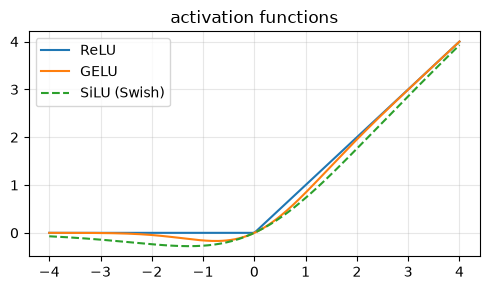

In [23]:
def gelu(z):   return 0.5 * z * (1 + np.tanh(np.sqrt(2 / np.pi) * (z + 0.044715 * z ** 3)))
def silu(z):   return z / (1 + np.exp(-z))

def ffn_gelu(x, W1, W2):        return gelu(x @ W1) @ W2
def ffn_swiglu(x, W1, W3, W2):  return (silu(x @ W1) * (x @ W3)) @ W2

d = 48
h_gelu, h_swi = 4 * d, int(8 * d / 3)
W1, W2 = rng.normal(0, 0.1, (d, h_gelu)), rng.normal(0, 0.1, (h_gelu, d))
S1, S3, S2 = rng.normal(0, 0.1, (d, h_swi)), rng.normal(0, 0.1, (d, h_swi)), rng.normal(0, 0.1, (h_swi, d))
xx = rng.normal(size=(3, d))
print("GELU FFN  : hidden", h_gelu, "params", W1.size + W2.size, "output", ffn_gelu(xx, W1, W2).shape)
print("SwiGLU FFN: hidden", h_swi, "params", S1.size + S3.size + S2.size, "output", ffn_swiglu(xx, S1, S3, S2).shape)

z = np.linspace(-4, 4, 200)
plt.figure(figsize=(5, 3))
plt.plot(z, np.maximum(z, 0), label="ReLU"); plt.plot(z, gelu(z), label="GELU"); plt.plot(z, silu(z), "--", label="SiLU (Swish)")
plt.legend(); plt.title("activation functions"); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

### 4.4 Dropout

**What it is.** During training, randomly set a fraction $p$ of activations to zero and scale the survivors by $1/(1-p)$ ("inverted dropout"), so the expected value stays the same. At inference it is switched off. It fights overfitting by stopping the network from relying on any single unit. Large LLM pre-training runs often use $p = 0$ because they see each token about once and do not overfit; dropout matters more for fine-tuning small data and for small models like ours.

In [24]:
def dropout(x, p, training=True):
    if not training or p == 0: return x
    keep = rng.random(x.shape) > p
    return x * keep / (1 - p)

a = np.ones(100_000)
d_out = dropout(a, 0.1)
print("fraction zeroed:", (d_out == 0).mean().round(3), "| mean before", a.mean(), "after", d_out.mean().round(3))

fraction zeroed: 0.1 | mean before 1.0 after 1.0


### 4.5 One block in numpy

Putting 4.1-4.4 together (pre-norm, GELU FFN, no biases in the linear layers, like many modern models). The weight matrices are stored in PyTorch's `nn.Linear` layout (out_features, in_features), so we multiply by the transpose; this lets us load PyTorch weights directly in section 5.

In [25]:
def block_forward(x, p, n_heads, mask):
    """One pre-norm transformer block. x: (B,T,d). mask: (B or 1, 1, T, T_k) boolean, True = blocked."""
    h = layer_norm(x, p["ln1_g"], p["ln1_b"])
    q, k, v = np.split(h @ p["W_qkv"].T, 3, axis=-1)                # one fused matrix for Q, K, V
    q, k, v = split_heads(q, n_heads), split_heads(k, n_heads), split_heads(v, n_heads)
    s = q @ k.transpose(0, 1, 3, 2) / np.sqrt(q.shape[-1])
    att = softmax(np.where(mask, -np.inf, s))
    x = x + merge_heads(att @ v) @ p["W_o"].T                         # residual add 1
    h = layer_norm(x, p["ln2_g"], p["ln2_b"])
    x = x + gelu(h @ p["W_1"].T) @ p["W_2"].T                         # residual add 2
    return x, att, (k, v)

dd, hh = 16, 4
pb = {"ln1_g": np.ones(dd), "ln1_b": np.zeros(dd), "ln2_g": np.ones(dd), "ln2_b": np.zeros(dd),
      "W_qkv": rng.normal(0, 0.1, (3 * dd, dd)), "W_o": rng.normal(0, 0.1, (dd, dd)),
      "W_1": rng.normal(0, 0.1, (4 * dd, dd)), "W_2": rng.normal(0, 0.1, (dd, 4 * dd))}
xb = rng.normal(size=(2, 5, dd))
mask5 = np.triu(np.ones((5, 5), dtype=bool), 1)[None, None]
yb, att_b, _ = block_forward(xb, pb, hh, mask5)
print("block in", xb.shape, "-> out", yb.shape, "| attention", att_b.shape)

block in (2, 5, 16) -> out (2, 5, 16) | attention (2, 4, 5, 5)


### 4.6 Counting parameters

Per block (no biases, $d$ = model width, FFN ratio 4):

| Part | Matrices | Parameters |
|---|---|---|
| attention | $W_Q, W_K, W_V, W_O$ each $d\times d$ | $4d^2$ |
| FFN | $W_1: d\times 4d$, $W_2: 4d\times d$ | $8d^2$ |
| two LayerNorms | $\gamma, \beta$ each of length $d$ | $4d$ |
| **total per block** | | $\approx 12d^2$ |

Whole model: $N \approx V d \,(\text{embeddings, tied}) + T_{max} d \,(\text{learned positions}) + 12 L d^2$. The $12Ld^2$ part is the **non-embedding** parameter count that scaling laws usually use. A quick check: GPT-2 small has $L=12$, $d=768$, $V=50257$, $T_{max}=1024$.

In [26]:
def param_count(V, d, L, T_max, ffn_mult=4, learned_pos=True, tied=True, ln_bias=True):
    per_block = 4 * d * d + 2 * ffn_mult * d * d + (4 * d if ln_bias else 2 * d)
    emb = V * d * (1 if tied else 2) + (T_max * d if learned_pos else 0)
    final_ln = 2 * d if ln_bias else d
    return {"embeddings": emb, "blocks": L * per_block, "final norm": final_ln,
            "total": emb + L * per_block + final_ln, "12*L*d^2": 12 * L * d * d}

for k_, v_ in param_count(50257, 768, 12, 1024).items():
    print(f"GPT-2 small {k_:>11}: {v_/1e6:8.2f} M")
print("(published size: about 124 M; the small gap is GPT-2's bias vectors)")

GPT-2 small  embeddings:    39.38 M
GPT-2 small      blocks:    84.97 M
GPT-2 small  final norm:     0.00 M
GPT-2 small       total:   124.36 M
GPT-2 small    12*L*d^2:    84.93 M
(published size: about 124 M; the small gap is GPT-2's bias vectors)


### 4.7 Where the FLOPs go

A matrix multiply costs about **2 FLOPs per weight per token** (one multiply, one add). So a forward pass costs about $2N$ FLOPs per token, plus the attention core, which has no weights but grows with context length $T$ (Kaplan et al. 2020):

$$C_{\text{forward}} \approx 2N + 2\,L\,T\,d \quad\text{per token} \qquad (\text{the } 2LTd \text{ term counts } QK^\top \text{ and } AV \text{ for a token at average position } T/2)$$

The table below splits the per-token cost for an illustrative 7B-class configuration ($d=4096$, $L=32$, $V=32000$) at two context lengths.

In [27]:
def flops_per_token(d, L, V, T, ffn_mult=4):
    parts = {"Q,K,V,O projections": L * 2 * 4 * d * d,
             "FFN":                 L * 2 * 2 * ffn_mult * d * d,
             "attention scores+AV": L * 2 * 2 * T * d / 2,    # average position T/2
             "output layer (logits)": 2 * d * V}
    return parts

for T_ in [2048, 32768]:
    parts = flops_per_token(4096, 32, 32000, T_)
    tot = sum(parts.values())
    print(f"context {T_}: {tot/1e9:.1f} GFLOPs per token")
    for k_, v_ in parts.items():
        print(f"   {k_:<24}{100 * v_ / tot:6.1f} %")

context 2048: 13.7 GFLOPs per token
   Q,K,V,O projections       31.4 %
   FFN                       62.8 %
   attention scores+AV        3.9 %
   output layer (logits)      1.9 %
context 32768: 21.7 GFLOPs per token
   Q,K,V,O projections       19.8 %
   FFN                       39.5 %
   attention scores+AV       39.5 %
   output layer (logits)      1.2 %


## 5. The full forward pass, the loss, and training

### 5.1 The whole model in numpy

Stack the pieces: embeddings + positions, $L$ blocks, a final LayerNorm, and the tied unembedding. This version also supports a **KV cache** (section 6) and **padding masks** (section 6.6), so we write it once and reuse it everywhere.

Our toy configuration: $d = 64$, $h = 4$ heads ($d_{head} = 16$), $L = 2$ blocks, context $T_{max} = 64$, vocabulary $V$ from our BPE tokenizer.

In [28]:
CFG = dict(V=V, d=64, n_heads=4, L=2, T_max=64)

def gpt_forward(P, ids, cfg, start=0, cache=None, pad_mask=None, positions=None):
    """Numpy GPT forward pass.
    ids: (B, T_new) token ids.  start: how many earlier tokens are already in `cache`.
    cache: list with one (K, V) pair per layer, each (B, h, start, d_head), or None.
    pad_mask: (B, start+T_new) True for real tokens, False for <pad>.  positions: (B, T_new) or None.
    Returns logits (B, T_new, V), the new cache, attention maps and residual-stream snapshots."""
    B, Tn = ids.shape
    if positions is None:
        positions = np.arange(start, start + Tn)[None, :]
    x = P["tok_emb"][ids] + P["pos_emb"][positions]                         # (B, Tn, d)
    Tk = start + Tn                                                         # total keys visible
    mask = (np.arange(Tk)[None, :] > (start + np.arange(Tn))[:, None])[None, None]   # causal, (1,1,Tn,Tk)
    if pad_mask is not None:
        mask = mask | ~pad_mask[:, None, None, :]                           # also block <pad> keys
    new_cache, atts, resid = [], [], [x]
    for l, p in enumerate(P["layers"]):
        h = layer_norm(x, p["ln1_g"], p["ln1_b"])
        q, k, v = np.split(h @ p["W_qkv"].T, 3, axis=-1)
        q, k, v = (split_heads(t, cfg["n_heads"]) for t in (q, k, v))
        if cache is not None:                                               # reuse earlier K, V
            k = np.concatenate([cache[l][0], k], axis=2)
            v = np.concatenate([cache[l][1], v], axis=2)
        new_cache.append((k, v))
        s = q @ k.transpose(0, 1, 3, 2) / np.sqrt(q.shape[-1])
        att = softmax(np.where(mask, -1e9, s))          # -1e9 instead of -inf: fully padded rows stay finite
        x = x + merge_heads(att @ v) @ p["W_o"].T
        h = layer_norm(x, p["ln2_g"], p["ln2_b"])
        x = x + gelu(h @ p["W_1"].T) @ p["W_2"].T
        atts.append(att); resid.append(x)
    logits = layer_norm(x, P["lnf_g"], P["lnf_b"]) @ P["tok_emb"].T          # tied unembedding
    return logits, new_cache, atts, resid

### 5.2 The same model in PyTorch

The PyTorch version is written independently (it uses PyTorch's built-in `scaled_dot_product_attention`). If both give the same numbers from the same weights, our numpy maths is right.

In [29]:
class TorchBlock(nn.Module):
    def __init__(self, d, n_heads):
        super().__init__()
        self.n_heads = n_heads
        self.ln1, self.ln2 = nn.LayerNorm(d), nn.LayerNorm(d)
        self.qkv = nn.Linear(d, 3 * d, bias=False)
        self.o = nn.Linear(d, d, bias=False)
        self.fc1, self.fc2 = nn.Linear(d, 4 * d, bias=False), nn.Linear(4 * d, d, bias=False)

    def forward(self, x):
        B, T, d = x.shape
        q, k, v = self.qkv(self.ln1(x)).split(d, dim=-1)
        q, k, v = (t.view(B, T, self.n_heads, d // self.n_heads).transpose(1, 2) for t in (q, k, v))
        y = F.scaled_dot_product_attention(q, k, v, is_causal=True)          # (B, h, T, d_head)
        x = x + self.o(y.transpose(1, 2).reshape(B, T, d))
        return x + self.fc2(F.gelu(self.fc1(self.ln2(x)), approximate="tanh"))

class TorchGPT(nn.Module):
    def __init__(self, V, d, n_heads, L, T_max):
        super().__init__()
        self.tok_emb, self.pos_emb = nn.Embedding(V, d), nn.Embedding(T_max, d)
        self.blocks = nn.ModuleList([TorchBlock(d, n_heads) for _ in range(L)])
        self.ln_f = nn.LayerNorm(d)
        for prm in self.parameters():                                        # small random start (GPT-2 style)
            if prm.dim() == 2: nn.init.normal_(prm, 0.0, 0.02)

    def forward(self, idx):
        x = self.tok_emb(idx) + self.pos_emb(torch.arange(idx.shape[1]))
        for blk in self.blocks:
            x = blk(x)
        return self.ln_f(x) @ self.tok_emb.weight.T                         # tied output layer

def to_numpy_params(m):
    """Copy PyTorch weights into the dict that gpt_forward expects (float64)."""
    g = lambda t: t.detach().double().numpy().copy()
    return {"tok_emb": g(m.tok_emb.weight), "pos_emb": g(m.pos_emb.weight),
            "lnf_g": g(m.ln_f.weight), "lnf_b": g(m.ln_f.bias),
            "layers": [{"ln1_g": g(b.ln1.weight), "ln1_b": g(b.ln1.bias), "ln2_g": g(b.ln2.weight),
                        "ln2_b": g(b.ln2.bias), "W_qkv": g(b.qkv.weight), "W_o": g(b.o.weight),
                        "W_1": g(b.fc1.weight), "W_2": g(b.fc2.weight)} for b in m.blocks]}

torch.manual_seed(SEED)
model = TorchGPT(**CFG)
n_torch = sum(p_.numel() for p_ in model.parameters())                     # shared (tied) weights counted once
calc = param_count(CFG["V"], CFG["d"], CFG["L"], CFG["T_max"])
print(f"PyTorch counts {n_torch:,} parameters; our formula says {calc['total']:,}; 12*L*d^2 = {calc['12*L*d^2']:,}")

ids_check = np.array([tok.encode("the cat sees a book at home.", bos=True)])
P0 = to_numpy_params(model)
np_logits = gpt_forward(P0, ids_check, CFG)[0]
with torch.no_grad():
    t_logits = model(torch.tensor(ids_check)).double().numpy()
print("max |numpy - torch| logits difference:", f"{np.abs(np_logits - t_logits).max():.2e}")

PyTorch counts 114,304 parameters; our formula says 114,304; 12*L*d^2 = 98,304
max |numpy - torch| logits difference: 2.06e-07


The formula matches PyTorch exactly, and the two implementations agree to about $10^{-7}$ (float32 rounding). Embeddings are about 13% of our toy's parameters and about 30% of GPT-2 small's; in a 7B model they are only a few percent, so $12Ld^2$ becomes a good estimate of the whole.

### 5.3 Logits, softmax over the vocabulary, cross-entropy and perplexity

For each position $t$ the model outputs $V$ **logits** (raw scores). Softmax turns them into a probability for every possible next token:

$$p(x_{t+1} = j \mid x_{\le t}) = \frac{e^{z_j}}{\sum_{k=1}^{V} e^{z_k}}$$

**Shifted targets.** One sequence gives $T$ training examples at once: the input is tokens $0..T-1$ and the target is tokens $1..T$ (the same sequence shifted left by one). Thanks to the causal mask, position $t$ only sees tokens up to $t$, so it cannot cheat.

```
input : <bos>  the   cat   sees   a    book
target:  the   cat   sees   a    book   .
```

**Cross-entropy loss** is the average "surprise" at the correct next token:

$$\mathcal{L} = -\frac{1}{T}\sum_{t=1}^{T} \log p(x_{t+1} \mid x_{\le t}), \qquad \text{perplexity} = e^{\mathcal{L}}$$

**Perplexity** reads as "the model is as unsure as if it picked uniformly among this many tokens". A random model has loss $\approx \ln V$, perplexity $\approx V$.

In [30]:
def cross_entropy_np(logits, targets):
    """Mean of -log p(target). logits (N,V), targets (N,)."""
    z = logits - logits.max(-1, keepdims=True)
    log_probs = z - np.log(np.exp(z).sum(-1, keepdims=True))         # log-softmax, numerically safe
    return -log_probs[np.arange(len(targets)), targets].mean()

seq = np.array(tok.encode("the cat sees a book.", bos=True, eos=True))
inp, tgt = seq[:-1], seq[1:]                                          # the shift
print("input :", [tok.itos[i] for i in inp])
print("target:", [tok.itos[i] for i in tgt])
lg = gpt_forward(P0, inp[None], CFG)[0][0]
loss0 = cross_entropy_np(lg, tgt)
print(f"untrained loss {loss0:.3f}  (ln V = {math.log(V):.3f}) | perplexity {math.exp(loss0):.1f}  (V = {V})")

input : ['<bos>', 'the', ' cat', ' sees', ' a', ' book', '.']
target: ['the', ' cat', ' sees', ' a', ' book', '.', '<eos>']
untrained loss 5.162  (ln V = 5.170) | perplexity 174.5  (V = 176)


### 5.4 Train the tiny model

We concatenate all training lines (each wrapped in `<bos>` ... `<eos>`) into one long stream of ids and cut random windows of 64 tokens. The optimiser is **AdamW** (Adam with weight decay), with a learning rate that **warms up** and then follows a **cosine decay** (explained in section 7), and **gradient clipping** (rescale the gradient if its length exceeds 1.0) for stability.

In [31]:
def encode_lines(ls):
    out = []
    for l in ls: out += tok.encode(l, bos=True, eos=True)
    return np.array(out)

train_ids, val_ids = encode_lines(train_lines), encode_lines(val_lines)
print("training stream:", len(train_ids), "tokens | validation stream:", len(val_ids), "tokens")

def get_batch(data, B, T, g):
    ix = g.integers(0, len(data) - T - 1, size=B)
    x = np.stack([data[i:i + T] for i in ix]); y = np.stack([data[i + 1:i + T + 1] for i in ix])
    return torch.tensor(x), torch.tensor(y)

def lr_at(step, max_lr, warmup, total, min_ratio=0.1):
    if step < warmup:                                                 # linear warm-up
        return max_lr * (step + 1) / warmup
    progress = (step - warmup) / max(1, total - warmup)                # 0 -> 1
    return max_lr * (min_ratio + (1 - min_ratio) * 0.5 * (1 + math.cos(math.pi * progress)))

@torch.no_grad()
def sample_torch(m, n_tokens=24, temperature=0.8, seed=0):
    g = torch.Generator().manual_seed(seed)
    ids = torch.tensor([[BOS]])
    for _ in range(n_tokens):
        probs = F.softmax(m(ids[:, -CFG["T_max"]:])[0, -1] / temperature, dim=-1)
        nxt = torch.multinomial(probs, 1, generator=g)
        if nxt.item() == EOS: break
        ids = torch.cat([ids, nxt[None]], dim=1)
    return tok.decode(ids[0].tolist())

@torch.no_grad()
def eval_loss(m, data, g, n_batches=8):
    m.eval()
    ls = [F.cross_entropy(m(x).view(-1, V), y.view(-1)).item() for x, y in (get_batch(data, 32, CFG["T_max"], g) for _ in range(n_batches))]
    m.train(); return float(np.mean(ls))

training stream: 14460 tokens | validation stream: 1580 tokens


In [32]:
STEPS, BATCH, MAX_LR, WARMUP = 600, 32, 3e-3, 40
torch.manual_seed(SEED)
model = TorchGPT(**CFG)
opt = torch.optim.AdamW(model.parameters(), lr=MAX_LR, betas=(0.9, 0.95), weight_decay=0.1)
g_train, g_eval = np.random.default_rng(1), np.random.default_rng(2)
history = {"step": [], "train": [], "val": [], "lr": []}
print("step 0 sample:", repr(sample_torch(model)))
t0 = time.time()
for step in range(STEPS):
    for group in opt.param_groups:
        group["lr"] = lr_at(step, MAX_LR, WARMUP, STEPS)
    x, y = get_batch(train_ids, BATCH, CFG["T_max"], g_train)
    loss = F.cross_entropy(model(x).view(-1, V), y.view(-1))          # shifted targets
    opt.zero_grad(); loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    opt.step()
    history["step"].append(step); history["train"].append(loss.item()); history["lr"].append(opt.param_groups[0]["lr"])
    if step in (100, 300) or step == STEPS - 1:
        vl = eval_loss(model, val_ids, g_eval)
        history["val"].append((step, vl))
        print(f"step {step:>3} | train loss {loss.item():.3f} | val loss {vl:.3f} (perplexity {math.exp(vl):.2f}) | sample: {sample_torch(model, seed=step)!r}")
train_seconds = time.time() - t0
model.eval()
print(f"training took {train_seconds:.1f} s on CPU")

step 0 sample: ' w sist child happ rivo n riverl n bo wa hu bird seeer very table sit doga ho h'


step 100 | train loss 0.808 | val loss 0.801 (perplexity 2.23) | sample: 'the cat is sleepy.'


step 300 | train loss 0.673 | val loss 0.696 (perplexity 2.01) | sample: 'the cat is sleepy.'


step 599 | train loss 0.656 | val loss 0.695 (perplexity 2.00) | sample: 'the teacher and a bird sleep on the table.'
training took 10.2 s on CPU


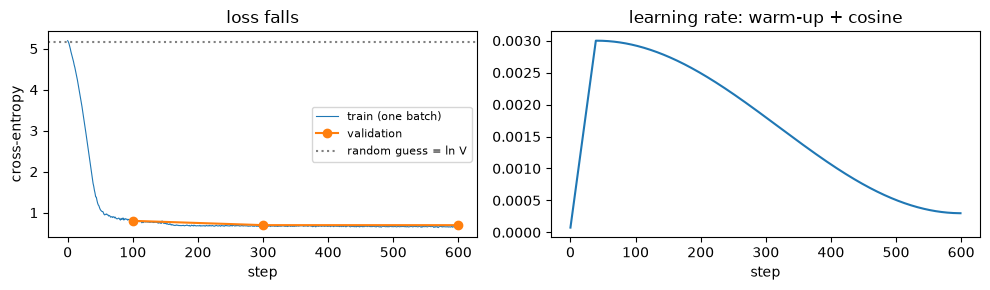

trained model: max |numpy - torch| difference: 3.93e-06


In [33]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].plot(history["train"], lw=0.8, label="train (one batch)")
ax[0].plot(*zip(*history["val"]), "o-", label="validation")
ax[0].axhline(math.log(V), ls=":", c="gray", label="random guess = ln V")
ax[0].set_xlabel("step"); ax[0].set_ylabel("cross-entropy"); ax[0].legend(fontsize=8); ax[0].set_title("loss falls")
ax[1].plot(history["lr"]); ax[1].set_xlabel("step"); ax[1].set_title("learning rate: warm-up + cosine")
plt.tight_layout(); plt.show()

P = to_numpy_params(model)                                            # trained weights for the numpy model
with torch.no_grad():
    t_logits = model(torch.tensor(ids_check)).double().numpy()
print("trained model: max |numpy - torch| difference:", f"{np.abs(gpt_forward(P, ids_check, CFG)[0] - t_logits).max():.2e}")

The samples go from random token soup to grammatical sentences of our toy language. The validation perplexity ends up small because the toy grammar is very predictable (after "the cat" there are only a handful of valid next words). Real text has much higher perplexity.

## 6. Generation

### 6.1 The autoregressive loop

Generation is just the forward pass in a loop: run the model, take the logits at the **last** position, pick a token, append it, repeat until a **stop token** or a length limit.

In [34]:
def generate_np(P, prompt_ids, max_new, use_cache=True, pick=None, stop_at_eos=True):
    """Generate with the numpy model. pick(logits) -> token id; defaults to greedy (argmax)."""
    pick = pick or (lambda z: int(np.argmax(z)))
    ids = list(prompt_ids)
    if use_cache:
        logits, cache, _, _ = gpt_forward(P, np.array([ids]), CFG)            # PREFILL: whole prompt at once
    for _ in range(max_new):
        if not use_cache:
            logits = gpt_forward(P, np.array([ids]), CFG)[0]                 # recompute everything every step
        nxt = pick(logits[0, -1])
        ids.append(nxt)
        if (stop_at_eos and nxt == EOS) or len(ids) >= CFG["T_max"]:
            break
        if use_cache:                                                        # DECODE: one new token only
            logits, cache, _, _ = gpt_forward(P, np.array([[nxt]]), CFG, start=len(ids) - 1, cache=cache)
    return ids

for prompt in ["the cat", "my sister and", "the teacher is"]:
    out = generate_np(P, tok.encode(prompt, bos=True), 20)
    print(f"{prompt!r:>18} -> {tok.decode(out)!r}")

         'the cat' -> 'the cat is very quiet.<eos>'
   'my sister and' -> 'my sister and the dog play in the garden.<eos>'
  'the teacher is' -> 'the teacher is hungry.<eos>'


### 6.2 Prefill vs decode

| | **Prefill** | **Decode** |
|---|---|---|
| What | process the whole prompt in one forward pass | produce one new token per forward pass |
| Work per pass | many tokens: big matrix-matrix multiplies | one token: matrix-vector multiplies |
| Bottleneck | arithmetic (compute-bound) | reading the weights and KV cache from memory (memory-bound) |
| User sees it as | time to first token (TTFT) | time between tokens (inter-token latency) |

In decode, every step reads **all** the weights to do very little maths with them, which is why batching many users together (and quantisation) speeds up serving so much. Details: [23_llm_caching_kv_cache_prompt_semantic_cag, section 2](23_llm_caching_kv_cache_prompt_semantic_cag.ipynb).

### 6.3 The KV cache

**What it is.** When we add token $t+1$, the keys and values of tokens $0..t$ do not change (thanks to the causal mask, earlier tokens never look at later ones). So we **store** each layer's $K$ and $V$ and, for each new token, compute only its own $q, k, v$ and attend to the stored ones.

**Cost.** Without a cache, step $t$ re-runs all $t$ tokens, so generating $n$ tokens costs about $\sum t \approx n^2/2$ token-passes. With a cache it is $n$ token-passes (plus attention reads that grow with $t$).

`generate_np` above already has both paths. Let us check they produce **identical** tokens, and time them (we disable the stop token so both generate the same number of tokens).

In [35]:
prompt_ids = tok.encode("the dog", bos=True)
a = generate_np(P, prompt_ids, 60, use_cache=False, stop_at_eos=False)
b = generate_np(P, prompt_ids, 60, use_cache=True,  stop_at_eos=False)
print("identical outputs:", a == b, "| tokens generated:", len(a) - len(prompt_ids))

# logits check: last-step logits from the cached path vs a full recompute
full_last = gpt_forward(P, np.array([b[:-1]]), CFG)[0][0, -1]
_, cache, _, _ = gpt_forward(P, np.array([b[:-2]]), CFG)
cached_last = gpt_forward(P, np.array([[b[-2]]]), CFG, start=len(b) - 2, cache=cache)[0][0, -1]
print("max logit difference, cached vs full:", f"{np.abs(full_last - cached_last).max():.2e}")

def best_time(fn, reps=3):
    ts = []
    for _ in range(reps):
        t0 = time.perf_counter(); fn(); ts.append(time.perf_counter() - t0)
    return min(ts)
t_no = best_time(lambda: generate_np(P, prompt_ids, 60, use_cache=False, stop_at_eos=False))
t_kv = best_time(lambda: generate_np(P, prompt_ids, 60, use_cache=True, stop_at_eos=False))
print(f"no cache: {t_no*1000:.1f} ms | KV cache: {t_kv*1000:.1f} ms | speed-up {t_no/t_kv:.1f}x (grows with length)")

identical outputs: True | tokens generated: 60
max logit difference, cached vs full: 1.89e-15


no cache: 95.0 ms | KV cache: 31.4 ms | speed-up 3.0x (grows with length)


**KV cache memory formula.** For every layer, every KV head, every token, we store one key and one value vector of length $d_{head}$:

$$\text{bytes} = 2 \times L \times n_{kv} \times d_{head} \times T \times B \times \text{bytes per number}$$

(the first 2 is "K and V"). This often limits how many users or how much context fits on a GPU. The configurations below are illustrative, not a specific product.

In [36]:
def kv_cache_bytes(L, n_kv, d_head, T, B=1, bytes_per=2):
    return 2 * L * n_kv * d_head * T * B * bytes_per

print(f"toy model, 64 tokens, float64: {kv_cache_bytes(2, 4, 16, 64, bytes_per=8)/1024:.0f} KiB")
for name, L_, nkv, dh in [("8B-class, MHA (32 KV heads)", 32, 32, 128), ("8B-class, GQA (8 KV heads)", 32, 8, 128)]:
    for T_ in [8192, 131072]:
        print(f"{name:<30} T={T_:>6}, fp16: {kv_cache_bytes(L_, nkv, dh, T_)/2**30:6.1f} GiB per sequence")

toy model, 64 tokens, float64: 128 KiB
8B-class, MHA (32 KV heads)    T=  8192, fp16:    4.0 GiB per sequence
8B-class, MHA (32 KV heads)    T=131072, fp16:   64.0 GiB per sequence
8B-class, GQA (8 KV heads)     T=  8192, fp16:    1.0 GiB per sequence
8B-class, GQA (8 KV heads)     T=131072, fp16:   16.0 GiB per sequence


### 6.4 Sampling: turning logits into a choice

| Method | Rule | Effect |
|---|---|---|
| **greedy** | pick $\arg\max_j z_j$ | deterministic; can loop or be bland |
| **temperature** $\tau$ | $p_j \propto e^{z_j/\tau}$ | $\tau<1$ sharper, $\tau>1$ flatter, $\tau \to 0$ is greedy |
| **top-k** | keep the $k$ most likely tokens, renormalise | fixed-size shortlist |
| **top-p (nucleus)** | keep the smallest set whose probabilities sum to $\ge p$ | shortlist size adapts to confidence |
| **min-p** | keep tokens with $p_j \ge p_{min} \cdot \max_k p_k$ | cut-off scales with the top token's probability |

The settings are applied in a chain (temperature, then a filter, then a random draw). The effect on a real model is shown in [00_start_here_how_llms_work, section 2](00_start_here_how_llms_work.ipynb) and [24_how_llms_differ_from_each_other, section 14](24_how_llms_differ_from_each_other.ipynb). Here is each rule in a few lines, applied to our model's next-token distribution after "the cat sees".

In [37]:
def filt_temperature(z, t):  return z / t
def filt_top_k(z, k):
    out = np.full_like(z, -np.inf); top = np.argsort(z)[-k:]; out[top] = z[top]; return out
def filt_top_p(z, p):
    probs = softmax(z); order = np.argsort(-probs)
    keep_n = np.searchsorted(np.cumsum(probs[order]), p) + 1          # smallest prefix reaching p
    out = np.full_like(z, -np.inf); out[order[:keep_n]] = z[order[:keep_n]]; return out
def filt_min_p(z, mp):
    probs = softmax(z); return np.where(probs >= mp * probs.max(), z, -np.inf)

z = gpt_forward(P, np.array([tok.encode("the cat sees", bos=True)]), CFG)[0][0, -1]
settings = {"plain (t=1)": z, "t=0.5": filt_temperature(z, 0.5), "t=2.0": filt_temperature(z, 2.0),
            "top-k k=3": filt_top_k(z, 3), "top-p p=0.9": filt_top_p(z, 0.9), "min-p 0.2": filt_min_p(z, 0.2)}
top_tokens = np.argsort(-z)[:6]
print(f"{'setting':<12}{'#kept':>6}  " + "".join(f"{tok.itos[i]!r:>10}" for i in top_tokens))
for name, zz in settings.items():
    pr = softmax(zz)
    print(f"{name:<12}{int((pr > 1e-12).sum()):>6}  " + "".join(f"{pr[i]:>10.3f}" for i in top_tokens))
print("greedy picks:", repr(tok.itos[int(np.argmax(z))]))

setting      #kept        ' a'    ' the'   ' some'   ' book'    ' red'     ' my'
plain (t=1)    176       0.405     0.391     0.200     0.001     0.001     0.000
t=0.5           55       0.460     0.428     0.112     0.000     0.000     0.000
t=2.0          176       0.306     0.300     0.215     0.013     0.013     0.009
top-k k=3        3       0.407     0.392     0.201     0.000     0.000     0.000
top-p p=0.9      3       0.407     0.392     0.201     0.000     0.000     0.000
min-p 0.2        3       0.407     0.392     0.201     0.000     0.000     0.000
greedy picks: ' a'


In [38]:
def make_sampler(t=1.0, top_k=None, top_p=None, min_p=None, seed=0):
    g = np.random.default_rng(seed)
    def pick(z):
        z = filt_temperature(z, t)
        if top_k: z = filt_top_k(z, top_k)
        if top_p: z = filt_top_p(z, top_p)
        if min_p: z = filt_min_p(z, min_p)
        return int(g.choice(len(z), p=softmax(z)))
    return pick

for label, kw in [("t=0.7, top-p 0.9", dict(t=0.7, top_p=0.9)), ("t=1.5 (no filter)", dict(t=1.5)), ("t=1.5, min-p 0.1", dict(t=1.5, min_p=0.1))]:
    outs = [tok.decode(generate_np(P, [BOS], 25, pick=make_sampler(seed=s, **kw))) for s in range(3)]
    print(label); [print("   ", repr(o)) for o in outs]

t=0.7, top-p 0.9
    'the teacher is sleepy.<eos>'
    'the cat is happy.<eos>'
    'a small child is hungry.<eos>'
t=1.5 (no filter)
    'the teacher is and my sister sit under the tree.<eos>'
    'the cat is happy.<eos>'
    'a small child is hungry.<eos>'
t=1.5, min-p 0.1
    'the teacher is sleepy.<eos>'
    'the cat is happy.<eos>'
    'a small child is hungry.<eos>'


Our toy language is so predictable that most settings give similar sentences. Look for the difference at high temperature: with no filter a low-probability token can slip through and break the grammar, while min-p (same random seeds) cuts those tail tokens off. On a real model the differences are much larger.

### 6.5 Stop tokens

Generation stops when the model emits a **stop token** (our `<eos>`; chat models use an end-of-turn token such as `<|im_end|>`), when a **stop string** you specify appears in the decoded text (checked after each step), or when `max_new_tokens` is reached. Our model learned to emit `<eos>` after each sentence because every training line ended with one, so `generate_np` stops on its own. If a fine-tuned model never learned its stop token, it rambles on: a classic chat-template bug.

### 6.6 Batching with padding and attention masks

**Why batch.** Decode is memory-bound, so serving 32 users at once costs barely more per step than serving one. But prompts have different lengths, and arrays must be rectangular, so we **pad** short prompts with `<pad>`.

**How it works.**
1. **Left-pad** for generation, so every prompt's last token sits in the same column and new tokens append in one column for everyone.
2. Build a **padding mask** (1 = real token) and combine it with the causal mask so no real token attends to a pad.
3. Give positions that **start at 0 at the first real token** (otherwise the padded prompt is "shifted" in position).

The check: the last-token logits from the batched run must match running each prompt alone.

In [39]:
prompts = ["the cat", "my sister and the old man"]
enc = [tok.encode(p_, bos=True) for p_ in prompts]
Tm = max(len(e) for e in enc)
batch = np.array([[PAD] * (Tm - len(e)) + e for e in enc])                     # left padding
pad_mask = batch != PAD
positions = np.maximum(np.cumsum(pad_mask, axis=1) - 1, 0)                     # 0 at the first real token
print("batch ids:\n", batch)
print("padding mask (1 = real):\n", pad_mask.astype(int))

masked_logits = gpt_forward(P, batch, CFG, pad_mask=pad_mask, positions=positions)[0][:, -1]
naive_logits  = gpt_forward(P, batch, CFG)[0][:, -1]                            # forgets the mask
for i, e in enumerate(enc):
    alone = gpt_forward(P, np.array([e]), CFG)[0][0, -1]
    print(f"prompt {i}: with mask diff {np.abs(masked_logits[i] - alone).max():.1e} | "
          f"without mask diff {np.abs(naive_logits[i] - alone).max():.1e}")

batch ids:
 [[ 0  0  0  0  1 32 96]
 [ 1 73 76 95 33 70 72]]
padding mask (1 = real):
 [[0 0 0 0 1 1 1]
 [1 1 1 1 1 1 1]]
prompt 0: with mask diff 0.0e+00 | without mask diff 4.8e+00
prompt 1: with mask diff 0.0e+00 | without mask diff 0.0e+00


The un-padded prompt matches either way, but the padded one is only correct with the mask and shifted positions. Real servers go further with **continuous batching** (finished sequences leave and new ones join at every step) and **paged KV caches**: see [13_inference_optimization](13_inference_optimization.ipynb) and [24_how_llms_differ_from_each_other, section 16.4](24_how_llms_differ_from_each_other.ipynb).

## 7. Training an LLM at scale, in simple words

Our toy run is the same recipe as a frontier pre-training run, just about a billion times smaller. Here is what changes with scale.

### 7.1 Objective and data

**Pre-training objective:** exactly the next-token cross-entropy from section 5.3, averaged over trillions of tokens. No labels are needed: the text is its own answer key ("self-supervised").

**Data mixture:** the training set is a blend of sources, each filtered, de-duplicated and weighted. Exact recipes are usually not published and change quickly, so treat this as a general picture:

| Source | Why it is included |
|---|---|
| filtered web pages | breadth of language and world knowledge |
| code | programming ability; also seems to help step-by-step reasoning |
| books, encyclopedias, papers | long, well-edited text and facts |
| maths and science | symbolic reasoning |
| many languages | multilingual ability (also needs a tokenizer that handles them, section 1) |
| synthetic and instruction-like data (often near the end) | targeted skills before post-training |

### 7.2 How many tokens per parameter? (Chinchilla)

Hoffmann et al. 2022 ("Training Compute-Optimal Large Language Models") found that for a fixed compute budget, loss is lowest when parameters $N$ and training tokens $D$ grow together, at roughly

$$D \approx 20\,N \quad (\text{a rule of thumb, not a law}).$$

Many recent models train on far more tokens than this ("over-training"), because a smaller model trained longer is **cheaper to serve**, and serving cost often dominates over the model's lifetime.

### 7.3 The $6ND$ compute rule

Training FLOPs $\approx 6ND$: the forward pass costs about $2N$ per token (section 4.7), and the backward pass about twice that, $4N$ (gradients with respect to both the activations and the weights). If you also fix $D = 20N$, then $C = 120 N^2$, so $N = \sqrt{C/120}$.

In [40]:
def train_flops(N, D): return 6 * N * D

def chinchilla_optimal(C):
    N = math.sqrt(C / 120); return N, 20 * N

# Illustrative hardware assumption, NOT a specific product: 1e15 FLOP/s peak per accelerator at 40% utilisation
EFFECTIVE = 1e15 * 0.40
for N, D in [(1e9, 20e9), (7e9, 2e12), (70e9, 15e12)]:
    C = train_flops(N, D)
    print(f"N = {N/1e9:>4.0f}B, D = {D/1e12:>5.2f}T tokens -> C = {C:.2e} FLOPs "
          f"= {C / EFFECTIVE / 86400:>9,.0f} accelerator-days (illustrative)")
N_opt, D_opt = chinchilla_optimal(1e24)
print(f"\nbudget 1e24 FLOPs -> compute-optimal about N = {N_opt/1e9:.0f}B parameters, D = {D_opt/1e12:.1f}T tokens")

N_toy = sum(p_.numel() for p_ in model.parameters())
D_toy = STEPS * BATCH * CFG["T_max"]
print(f"\nour toy run: N = {N_toy:,}, D = {D_toy:,} tokens -> 6ND = {train_flops(N_toy, D_toy):.2e} FLOPs "
      f"in {train_seconds:.1f} s = about {train_flops(N_toy, D_toy)/train_seconds/1e9:.1f} GFLOP/s achieved on this CPU")

N =    1B, D =  0.02T tokens -> C = 1.20e+20 FLOPs =         3 accelerator-days (illustrative)
N =    7B, D =  2.00T tokens -> C = 8.40e+22 FLOPs =     2,431 accelerator-days (illustrative)
N =   70B, D = 15.00T tokens -> C = 6.30e+24 FLOPs =   182,292 accelerator-days (illustrative)

budget 1e24 FLOPs -> compute-optimal about N = 91B parameters, D = 1.8T tokens

our toy run: N = 114,304, D = 1,228,800 tokens -> 6ND = 8.43e+11 FLOPs in 10.2 s = about 82.8 GFLOP/s achieved on this CPU


### 7.4 Memory per parameter: training vs inference

| Item (mixed-precision training with AdamW) | Bytes per parameter |
|---|---|
| weights in bf16 (used for the forward and backward pass) | 2 |
| gradients in bf16 | 2 |
| fp32 "master" copy of the weights (for precise updates) | 4 |
| Adam first moment $m$ (fp32) | 4 |
| Adam second moment $v$ (fp32) | 4 |
| **total, before activations** | **about 16** |

**Inference** needs only the weights: 2 bytes (bf16), 1 (int8) or about 0.5 (int4), **plus the KV cache** (section 6.3). **Activations** (intermediate results saved for the backward pass) come on top in training and grow with batch size and sequence length; **activation checkpointing** trades extra compute for less memory by recomputing them. Exact numbers vary by setup; this is the standard back-of-envelope. You can see the two Adam states in our toy optimiser:

In [41]:
state_numbers = sum(s["exp_avg"].numel() + s["exp_avg_sq"].numel() for s in opt.state.values())
print(f"toy: {N_toy:,} parameters -> Adam keeps {state_numbers:,} extra numbers (= 2 x N)")
print(f"\n{'model':>6} {'train (16 B/param)':>20} {'infer bf16':>12} {'infer int4':>12}")
for N in [1e9, 7e9, 70e9]:
    print(f"{N/1e9:>5.0f}B {N*16/1e9:>17.0f} GB {N*2/1e9:>9.0f} GB {N*0.5/1e9:>9.1f} GB")

toy: 114,304 parameters -> Adam keeps 228,608 extra numbers (= 2 x N)

 model   train (16 B/param)   infer bf16   infer int4
    1B                16 GB         2 GB       0.5 GB
    7B               112 GB        14 GB       3.5 GB
   70B              1120 GB       140 GB      35.0 GB


### 7.5 Spreading the work over many accelerators

| Strategy | What is split | Analogy |
|---|---|---|
| **Data parallel** | each device has a full copy, gets different batches; gradients are averaged | many cooks, same recipe, different ingredients |
| **Sharded data parallel (ZeRO / FSDP)** | weights, gradients and optimiser states are split across devices and gathered when needed | each cook stores one chapter of the recipe book |
| **Tensor parallel** | each matrix multiply is split across devices (by columns/rows) | several cooks chop one onion together |
| **Pipeline parallel** | different layers live on different devices; micro-batches flow through | an assembly line |
| **Expert parallel** | MoE experts (section 9) live on different devices | specialist stations |
| **Sequence / context parallel** | a very long sequence is split across devices | reading a long book in parts |

Large runs combine several ("3D parallelism"). Code-level introduction: [05_Deep_Learning/11_distributed_training](../05_Deep_Learning/11_distributed_training.ipynb); tensor and pipeline parallel demos: [24_how_llms_differ_from_each_other, sections 16.6-16.7](24_how_llms_differ_from_each_other.ipynb).

### 7.6 Learning-rate warm-up, cosine decay and loss spikes

We used this schedule in section 5.4 (with $W$ warm-up steps out of $S$ total):

$$\eta(t) = \begin{cases} \eta_{max}\,\dfrac{t}{W} & t < W \\[2mm] \eta_{min} + \tfrac{1}{2}(\eta_{max}-\eta_{min})\left(1+\cos\!\left(\pi\,\dfrac{t-W}{S-W}\right)\right) & t \ge W \end{cases}$$

- **Warm-up**: at the start, Adam's moment estimates are noisy and the weights are random, so big steps can blow up. Start small.
- **Cosine decay**: large steps early to make progress, small steps late to settle into a good minimum. A popular alternative is **warmup-stable-decay (WSD)**: constant LR, then a short decay at the end, which makes it easy to continue training later.

**Loss spikes** are sudden jumps in training loss in large runs. Common causes: too high a learning rate, bad data batches, numerical overflow in attention logits. Common fixes: **gradient clipping** (below), lowering the LR, skipping the offending batches and restarting from the last checkpoint, and architectural guards such as QK-normalisation or a small "z-loss" that keeps logits from growing. Gradient clipping rescales the whole gradient vector $g$ when its length exceeds $c$:

$$g \leftarrow g \cdot \min\!\left(1, \frac{c}{\lVert g \rVert}\right)$$

In [42]:
def clip_by_norm(g, c):
    n = np.linalg.norm(g); return g * min(1.0, c / n), n

for g in [np.array([0.3, -0.4]), np.array([30.0, -40.0])]:
    clipped, n = clip_by_norm(g, 1.0)
    print(f"gradient {g} (norm {n:.1f}) -> {clipped} (norm {np.linalg.norm(clipped):.1f}); direction kept")

gradient [ 0.3 -0.4] (norm 0.5) -> [ 0.3 -0.4] (norm 0.5); direction kept
gradient [ 30. -40.] (norm 50.0) -> [ 0.6 -0.8] (norm 1.0); direction kept


## 8. After pre-training: SFT, LoRA, quantisation, preference tuning

A pre-trained model continues text; it does not yet follow instructions. **Post-training** turns it into an assistant. Hands-on versions of SFT, LoRA and DPO on CPU: [21_fine_tuning_hands_on_cpu](21_fine_tuning_hands_on_cpu.ipynb). Here we focus on the maths of each step.

### 8.1 Supervised fine-tuning (SFT): chat template and loss masking

**What it is.** Continue training on (instruction, good answer) pairs, written in a fixed **chat template** with special role tokens.

**Loss masking.** We want the model to learn to *write answers*, not to *predict the user's question*. So we compute the loss **only on the assistant tokens**: the labels of all other positions are set to an ignore value (PyTorch's convention is $-100$):

$$\mathcal{L}_{SFT} = -\frac{1}{|\mathcal{A}|}\sum_{t \in \mathcal{A}} \log p(x_{t+1} \mid x_{\le t}), \qquad \mathcal{A} = \text{positions whose target is an assistant token}$$

The template below is made up for the demo (each model family has its own), and the "tokenizer" is a simple word splitter standing in for a real one.

In [43]:
template = "<|user|> what does the cat want ? <|end|> <|assistant|> the cat wants some water . <|end|>"
toks = template.split()                                               # stand-in tokenizer: split on spaces
start_ans = toks.index("<|assistant|>") + 1                           # first token the model must learn to write
labels = [t if i >= start_ans else -100 for i, t in enumerate(toks)]  # -100 = "ignore in the loss"
print(f"{'token':<16}{'target used in loss?'}")
for t, lab in zip(toks, labels):
    print(f"{t:<16}{'yes' if lab != -100 else 'no (masked)'}")

# the masked loss equals the plain average over the answer positions only
vocab_demo = {w: i for i, w in enumerate(dict.fromkeys(toks))}
y_ids = torch.tensor([vocab_demo[t] if lab != -100 else -100 for t, lab in zip(toks, labels)])
logits_demo = torch.randn(len(toks), len(vocab_demo), generator=torch.Generator().manual_seed(0))
masked = F.cross_entropy(logits_demo, y_ids, ignore_index=-100)
manual = F.cross_entropy(logits_demo[start_ans:], y_ids[start_ans:])
print(f"\nmasked loss {masked.item():.4f} == loss on answer tokens only {manual.item():.4f}")

token           target used in loss?
<|user|>        no (masked)
what            no (masked)
does            no (masked)
the             no (masked)
cat             no (masked)
want            no (masked)
?               no (masked)
<|end|>         no (masked)
<|assistant|>   no (masked)
the             yes
cat             yes
wants           yes
some            yes
water           yes
.               yes
<|end|>         yes

masked loss 2.2772 == loss on answer tokens only 2.2772


(In a real setup the labels are also shifted by one position, exactly as in section 5.3; we skip that here to keep the table readable.)

### 8.2 LoRA: low-rank adapters

**What it is.** Freeze the pre-trained weight $W$ ($d \times k$) and learn a small **low-rank** correction instead:

$$W' = W + \frac{\alpha}{r}\,BA, \qquad B: d \times r,\quad A: r \times k,\quad r \ll \min(d, k)$$

- **Rank** $r$ (often 8-64) controls capacity. Trainable parameters drop from $dk$ to $r(d + k)$.
- $B$ starts at **zero**, so at the start $W' = W$ exactly: training begins from the original model.
- **Alpha** $\alpha$ is a scale; dividing by $r$ keeps the update size similar when you change $r$.
- After training you can **merge** $BA$ into $W$, so inference costs nothing extra; or keep many small adapters and swap them per task.

Paper: Hu et al. 2021, "LoRA". More variants (QLoRA, DoRA): [05_Deep_Learning/12_advanced_peft](../05_Deep_Learning/12_advanced_peft.ipynb).

In [44]:
class LoRALinear(nn.Module):
    """Wrap a frozen nn.Linear with a trainable low-rank update (alpha/r) * B @ A."""
    def __init__(self, base: nn.Linear, r=4, alpha=8):
        super().__init__()
        self.base = base
        for p_ in self.base.parameters(): p_.requires_grad_(False)          # freeze W
        self.A = nn.Parameter(torch.randn(r, base.in_features) * 0.01)      # r x k
        self.B = nn.Parameter(torch.zeros(base.out_features, r))            # d x r, zero at start
        self.scale = alpha / r
    def forward(self, x):
        return self.base(x) + self.scale * (x @ self.A.T @ self.B.T)
    def merged_weight(self):
        return self.base.weight + self.scale * self.B @ self.A

base = nn.Linear(64, 64, bias=False)
lora = LoRALinear(base, r=4, alpha=8)
xl = torch.randn(3, 64)
print("at start, LoRA output == base output:", torch.allclose(lora(xl), base(xl)))
with torch.no_grad(): lora.B.normal_(0, 0.1)                                # pretend we trained B
print("after 'training', merged weight gives the same output:",
      torch.allclose(lora(xl), xl @ lora.merged_weight().T, atol=1e-5))

for d_, r_ in [(64, 4), (4096, 8), (4096, 64)]:
    print(f"d=k={d_:>5}, r={r_:>2}: full {d_*d_:>11,} vs LoRA {r_*2*d_:>8,} trainable ({100*r_*2*d_/(d_*d_):.2f} %)")

at start, LoRA output == base output: True
after 'training', merged weight gives the same output: True
d=k=   64, r= 4: full       4,096 vs LoRA      512 trainable (12.50 %)
d=k= 4096, r= 8: full  16,777,216 vs LoRA   65,536 trainable (0.39 %)
d=k= 4096, r=64: full  16,777,216 vs LoRA  524,288 trainable (3.12 %)


In [45]:
import copy
lora_model = copy.deepcopy(model)
for p_ in lora_model.parameters(): p_.requires_grad_(False)                # freeze everything
for blk in lora_model.blocks:                                              # add adapters to attention only
    blk.qkv, blk.o = LoRALinear(blk.qkv, r=4, alpha=8), LoRALinear(blk.o, r=4, alpha=8)
trainable = sum(p_.numel() for p_ in lora_model.parameters() if p_.requires_grad)
total = sum(p_.numel() for p_ in lora_model.parameters())
print(f"toy model with LoRA on Q,K,V,O: {trainable:,} trainable of {total:,} ({100*trainable/total:.1f} %)")
with torch.no_grad():
    same = torch.allclose(lora_model(torch.tensor(ids_check)), model(torch.tensor(ids_check)), atol=1e-6)
print("untrained adapters leave the model unchanged:", same)

toy model with LoRA on Q,K,V,O: 3,072 trainable of 117,376 (2.6 %)
untrained adapters leave the model unchanged: True


### 8.3 Quantisation maths: int8 and int4

**What it is.** Store each weight with fewer bits: 8 or 4 instead of 16. A real number $w$ is mapped to an integer $q$ with a **scale** $s$ (and maybe a **zero-point** $z$), and mapped back when used.

**Symmetric** (zero stays exactly zero), with $b$ bits:

$$s = \frac{\max |w|}{2^{b-1}-1}, \qquad q = \text{round}(w / s), \qquad \hat{w} = s\,q$$

**Asymmetric** (uses the full range when values are not centred):

$$s = \frac{\max w - \min w}{2^b - 1}, \qquad z = \text{round}(-\min w / s), \qquad q = \text{clip}(\text{round}(w/s) + z,\, 0,\, 2^b-1), \qquad \hat{w} = s\,(q - z)$$

**Granularity.** One scale per tensor is crude: a single large **outlier** stretches the scale and wastes resolution for everyone else. Per-row (per-channel) or **per-group** scales (for example one scale per 32 or 128 weights) fix most of this, and are standard for int4. Error demo, then the effect on our trained toy model. More formats (GPTQ, AWQ, GGUF): [24_how_llms_differ_from_each_other, section 10](24_how_llms_differ_from_each_other.ipynb) and [05_Deep_Learning/13_quantization_and_compression_advanced](../05_Deep_Learning/13_quantization_and_compression_advanced.ipynb).

In [46]:
def quant_sym(w, bits, axis=None):
    qmax = 2 ** (bits - 1) - 1
    s = np.abs(w).max(axis=axis, keepdims=axis is not None) / qmax
    s = np.where(s == 0, 1.0, s)
    q = np.clip(np.round(w / s), -qmax, qmax)
    return q * s                                            # de-quantised values

def quant_asym(w, bits):
    s = (w.max() - w.min()) / (2 ** bits - 1); z = np.round(-w.min() / s)
    q = np.clip(np.round(w / s) + z, 0, 2 ** bits - 1)
    return s * (q - z)

def quant_group(w, bits, group=32):
    flat = w.reshape(-1, group)                             # one scale per group of 32 weights
    return quant_sym(flat, bits, axis=1).reshape(w.shape)

w = rng.normal(0, 0.02, size=4096)
w_out = w.copy(); w_out[7] = 0.5                            # one outlier, 25x the typical size
print(f"{'method':<28}{'mean |error|, normal':>22}{'with one outlier':>18}")
for name, fn in [("int8 symmetric, per-tensor", lambda a: quant_sym(a, 8)),
                 ("int8 asymmetric, per-tensor", lambda a: quant_asym(a, 8)),
                 ("int4 symmetric, per-tensor", lambda a: quant_sym(a, 4)),
                 ("int4 symmetric, groups of 32", lambda a: quant_group(a, 4))]:
    print(f"{name:<28}{np.abs(fn(w) - w).mean():>22.2e}{np.abs(fn(w_out) - w_out).mean():>18.2e}")

method                        mean |error|, normal  with one outlier
int8 symmetric, per-tensor                1.53e-04          9.93e-04
int8 asymmetric, per-tensor               1.39e-04          5.54e-04
int4 symmetric, per-tensor                2.75e-03          1.48e-02
int4 symmetric, groups of 32              1.63e-03          1.75e-03


In [47]:
def quantize_params(P, fn):
    Q_ = copy.deepcopy(P)
    Q_["tok_emb"] = fn(P["tok_emb"])
    for layer in Q_["layers"]:
        for kname in ["W_qkv", "W_o", "W_1", "W_2"]:
            layer[kname] = fn(layer[kname])
    return Q_

gq = np.random.default_rng(3)
val_starts = gq.integers(0, len(val_ids) - CFG["T_max"] - 1, size=16)
VX = np.stack([val_ids[i:i + CFG["T_max"]] for i in val_starts]); VY = np.stack([val_ids[i + 1:i + CFG["T_max"] + 1] for i in val_starts])
def np_val_loss(Pq):
    lg = gpt_forward(Pq, VX, CFG)[0]
    return cross_entropy_np(lg.reshape(-1, V), VY.reshape(-1))

for name, fn in [("float64 (original)", lambda a: a),
                 ("int8 per-row", lambda a: quant_sym(a, 8, axis=1)),
                 ("int4 per-row", lambda a: quant_sym(a, 4, axis=1)),
                 ("int4 groups of 32", lambda a: quant_group(a, 4)),
                 ("int4 per-tensor", lambda a: quant_sym(a, 4))]:
    print(f"{name:<20} validation loss {np_val_loss(quantize_params(P, fn)):.4f}")

float64 (original)   validation loss 0.6882


int8 per-row         validation loss 0.6885


int4 per-row         validation loss 0.6894


int4 groups of 32    validation loss 0.6859


int4 per-tensor      validation loss 0.6939


On this tiny model all variants stay close: int8 is practically free, per-tensor int4 is the worst, and the small differences among the others are mostly noise (one int4 variant even scores slightly lower). On large models, which have strong outlier features, the gap between per-tensor and per-group int4 is much bigger, as the outlier column above suggests.

### 8.4 Preference tuning: RLHF and DPO in formulas

**RLHF (reinforcement learning from human feedback)**, as in InstructGPT (Ouyang et al. 2022):
1. Collect pairs of answers to the same prompt where people marked the better one $y_w$ (winner) and the worse one $y_l$ (loser).
2. Train a **reward model** $r_\phi$ with the Bradley-Terry loss: $\;\mathcal{L}_{RM} = -\log \sigma\big(r_\phi(x, y_w) - r_\phi(x, y_l)\big)$.
3. Optimise the policy $\pi_\theta$ (the LLM) with RL (often PPO) to get high reward without drifting too far from the SFT model $\pi_{ref}$:

$$\max_{\pi_\theta}\; \mathbb{E}_{y \sim \pi_\theta}\big[r_\phi(x, y)\big] - \beta\, \text{KL}\big(\pi_\theta(\cdot|x)\,\|\,\pi_{ref}(\cdot|x)\big)$$

**DPO (direct preference optimisation)**, Rafailov et al. 2023, shows that the same goal can be reached with a simple classification-style loss on the pairs, no reward model and no RL loop:

$$\mathcal{L}_{DPO} = -\log \sigma\!\left(\beta\left[\log\frac{\pi_\theta(y_w|x)}{\pi_{ref}(y_w|x)} - \log\frac{\pi_\theta(y_l|x)}{\pi_{ref}(y_l|x)}\right]\right)$$

In words: raise the chosen answer's probability **relative to the reference** more than the rejected one's. Here $\log \pi(y|x)$ is the sum of the log-probabilities of the answer's tokens, which our toy model can compute. At the start $\pi_\theta = \pi_{ref}$, so the bracket is 0 and the loss is $\log 2$. Many variants (IPO, KTO, ORPO, SimPO, GRPO-style RL): [12_alignment_techniques](12_alignment_techniques.ipynb).

In [48]:
def seq_logprob(Pm, prompt, answer):
    """Sum of log p(answer tokens | prompt) under the numpy model."""
    p_ids, a_ids = tok.encode(prompt, bos=True), tok.encode(answer, eos=True)
    ids_ = np.array([p_ids + a_ids])
    lg = gpt_forward(Pm, ids_[:, :-1], CFG)[0][0]
    z = lg - lg.max(-1, keepdims=True); lp = z - np.log(np.exp(z).sum(-1, keepdims=True))
    tgt_ = ids_[0, 1:]
    return lp[np.arange(len(tgt_)), tgt_][len(p_ids) - 1:].sum()           # only the answer positions

def dpo_loss(lp_w, lp_l, ref_w, ref_l, beta=0.1):
    margin = beta * ((lp_w - ref_w) - (lp_l - ref_l))
    return -np.log(1 / (1 + np.exp(-margin)))

prompt = "the cat"
chosen, rejected = " sees a book at home.", " is is hungry."
ref_w, ref_l = seq_logprob(P, prompt, chosen), seq_logprob(P, prompt, rejected)
print(f"log p(chosen) = {ref_w:.2f}, log p(rejected) = {ref_l:.2f}")
print(f"DPO loss when policy == reference: {dpo_loss(ref_w, ref_l, ref_w, ref_l):.4f} (log 2 = {math.log(2):.4f})")
for shift in [2, 5, 10]:
    print(f"policy raises log p(chosen) by {shift:>2} and lowers log p(rejected) by {shift:>2} -> loss {dpo_loss(ref_w+shift, ref_l-shift, ref_w, ref_l):.4f}")

log p(chosen) = -5.68, log p(rejected) = -11.59
DPO loss when policy == reference: 0.6931 (log 2 = 0.6931)
policy raises log p(chosen) by  2 and lowers log p(rejected) by  2 -> loss 0.5130
policy raises log p(chosen) by  5 and lowers log p(rejected) by  5 -> loss 0.3133
policy raises log p(chosen) by 10 and lowers log p(rejected) by 10 -> loss 0.1269


## 9. Two alternatives inside the block: Mixture of Experts and state-space models

### 9.1 Mixture of Experts (MoE) from scratch

**What it is.** Replace the single FFN with $E$ smaller FFNs ("experts") and a **router** that sends each token to only the top-$k$ of them (often $k$ = 1, 2 or 8). The model has many parameters in total but uses only a few per token.

**Analogy.** A hospital with many specialists and a triage nurse: every patient sees only one or two doctors.

**How it works**, for a token vector $x$:

$$\text{router logits } g = xW_r \in \mathbb{R}^E, \quad \mathcal{T} = \text{top-}k(g), \quad w_i = \frac{e^{g_i}}{\sum_{j\in\mathcal{T}} e^{g_j}} \;(i\in\mathcal{T}), \quad y = \sum_{i \in \mathcal{T}} w_i\, \text{FFN}_i(x)$$

**Load balancing.** Left alone, the router tends to send everything to a few experts, which then over-train while others starve. The Switch Transformer (Fedus et al. 2021) adds an auxiliary loss:

$$\mathcal{L}_{balance} = E \sum_{i=1}^{E} f_i\, P_i, \qquad f_i = \text{fraction of tokens sent to expert } i, \quad P_i = \text{mean router probability for expert } i$$

It is about 1 when routing is even and grows when a few experts get most of the tokens (its smallest possible value is 1). (Some newer models balance with a per-expert bias term instead of, or as well as, this loss.) Model-level view (total vs active parameters): [24_how_llms_differ_from_each_other, section 2.2](24_how_llms_differ_from_each_other.ipynb).

In [49]:
def moe_layer(X, W_router, experts, top_k=2):
    """X: (n, d). experts: list of (W1, W2). Returns output, chosen experts, router probabilities."""
    logits = X @ W_router                                                 # (n, E)
    probs = softmax(logits)
    top = np.argsort(-logits, axis=1)[:, :top_k]                          # (n, k) chosen experts
    out = np.zeros_like(X)
    for t in range(X.shape[0]):
        w = softmax(logits[t, top[t]])                                     # renormalise over the chosen k
        for weight, e in zip(w, top[t]):
            W1e, W2e = experts[e]
            out[t] += weight * (gelu(X[t] @ W1e) @ W2e)
    return out, top, probs

def balance_loss(top, probs, E):
    f = np.bincount(top[:, 0], minlength=E) / len(top)                     # top-1 assignment fractions
    return E * np.sum(f * probs.mean(0)), f

n_tok, d_m, E_ = 512, 32, 8
Xm = rng.normal(size=(n_tok, d_m))
experts = [(rng.normal(0, 0.1, (d_m, 2 * d_m)), rng.normal(0, 0.1, (2 * d_m, d_m))) for _ in range(E_)]
W_even = rng.normal(0, 0.1, (d_m, E_))
W_skew = W_even.copy(); W_skew[:, 0] += 0.4 * Xm.mean(0) / np.linalg.norm(Xm.mean(0)) * 10   # favour expert 0

for name, Wr in [("random router", W_even), ("skewed router", W_skew)]:
    y_moe, top, probs = moe_layer(Xm, Wr, experts)
    lb, f = balance_loss(top, probs, E_)
    print(f"{name:<14} tokens per expert {np.round(f * n_tok).astype(int)} | balance loss {lb:.2f}")
dense_ffn = 2 * d_m * (2 * d_m)
print(f"parameters: total experts {E_ * dense_ffn:,}, active per token (top-2) {2 * dense_ffn:,}")

random router  tokens per expert [62 64 79 61 48 58 77 63] | balance loss 1.00


skewed router  tokens per expert [286  25  40  33  22  21  45  40] | balance loss 2.16
parameters: total experts 32,768, active per token (top-2) 8,192


### 9.2 A state-space (Mamba-style) recurrence in miniature

**What it is.** Instead of attention (every token looks at every past token, cost $O(T^2)$, a KV cache that grows), a **state-space model (SSM)** keeps a **fixed-size state** $h$ that is updated once per token, like an RNN but designed to train in parallel:

$$h_t = \bar{A}\, h_{t-1} + \bar{B}\, x_t, \qquad y_t = C\, h_t, \qquad \bar{A} = e^{\Delta A},\;\; \bar{B} \approx \Delta B$$

$\Delta$ is a step size that turns a continuous-time system into a per-token update ("discretisation").

- If $\bar A, \bar B, C$ are the **same for every token**, unrolling the recurrence gives a **convolution**: $y_t = \sum_{k} C\bar{A}^k\bar{B}\, x_{t-k}$, which can be computed for all $t$ in parallel during training (S4).
- **Mamba** (Gu and Dao 2023) makes $\Delta$, $B$ and $C$ **depend on the input** ("selective"), so the model can choose what to remember or forget. It is no longer a fixed convolution, but still a linear-time **scan**.
- Generation memory is constant: only $h$ is kept, however long the text. Many recent models are **hybrids** that mix SSM (or linear-attention) layers with a few full-attention layers. Survey: [14_llm_architecture_innovations](14_llm_architecture_innovations.ipynb).

In [50]:
N_state, T_s = 4, 30
A_diag = -np.array([0.2, 0.5, 1.0, 2.0])                      # stable (negative) diagonal A
Bv, Cv, delta = rng.normal(size=N_state), rng.normal(size=N_state), 0.5
xs_ = rng.normal(size=T_s)
Abar, Bbar = np.exp(delta * A_diag), delta * Bv

# 1) recurrence: one state update per token
h_ = np.zeros(N_state); y_rec = []
for x_t in xs_:
    h_ = Abar * h_ + Bbar * x_t
    y_rec.append(Cv @ h_)
# 2) the same thing as a convolution with kernel K_k = C Abar^k Bbar
Kker = np.array([Cv @ (Abar ** k_ * Bbar) for k_ in range(T_s)])
y_conv = [sum(Kker[k_] * xs_[t - k_] for k_ in range(t + 1)) for t in range(T_s)]
print("recurrence == convolution (time-invariant SSM):", np.allclose(y_rec, y_conv))

# 3) selective (Mamba-style): the step size depends on the input token
w_delta = 1.5
h_ = np.zeros(N_state); y_sel = []
for x_t in xs_:
    d_t = np.log1p(np.exp(w_delta * x_t))                     # softplus -> positive step size per token
    h_ = np.exp(d_t * A_diag) * h_ + d_t * Bv * x_t
    y_sel.append(Cv @ h_)
print(f"selective scan output for {T_s} tokens computed with a state of only {N_state} numbers;")
print(f"a KV cache for the same {T_s} tokens (1 layer, d=64) would hold {2 * T_s * 64} numbers and keep growing")

recurrence == convolution (time-invariant SSM): True
selective scan output for 30 tokens computed with a state of only 4 numbers;
a KV cache for the same 30 tokens (1 layer, d=64) would hold 3840 numbers and keep growing


## 10. Encoder-only vs decoder-only vs encoder-decoder

The building blocks are the same; what changes is **which tokens may look at which** (the mask) and **what the model is trained to predict**.

| Family | Examples | Attention mask | Training objective | Typical use |
|---|---|---|---|---|
| **Encoder-only** | BERT, RoBERTa, modern embedding models | bidirectional (everyone sees everyone) | **masked language modelling**: hide ~15% of tokens, predict them | classification, embeddings, search, NER |
| **Decoder-only** | GPT, Llama, Qwen and most chat models | causal | next-token prediction | text generation, chat, almost all LLMs today |
| **Encoder-decoder** | T5, BART, Whisper, many translation models | encoder bidirectional, decoder causal + cross-attention | **span corruption** (T5) or denoising (BART) | translation, summarisation, speech-to-text |

The masks as pictures (dark = may attend):

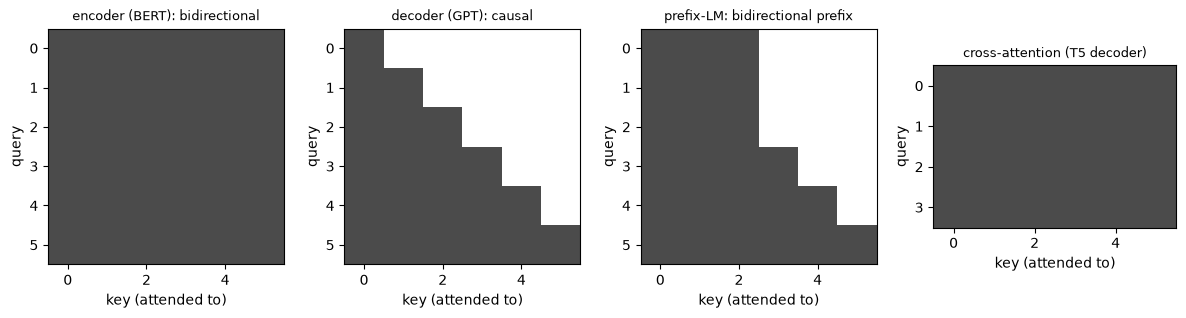

In [51]:
n = 6
bidir = np.ones((n, n)); causal_m = np.tril(np.ones((n, n)))
prefix = causal_m.copy(); prefix[:, :3] = 1                       # prefix-LM: first 3 tokens fully visible
cross = np.ones((4, n))                                           # 4 decoder tokens over 6 encoder tokens
fig, ax = plt.subplots(1, 4, figsize=(12, 3))
for a_, m_, t_ in zip(ax, [bidir, causal_m, prefix, cross],
                      ["encoder (BERT): bidirectional", "decoder (GPT): causal", "prefix-LM: bidirectional prefix", "cross-attention (T5 decoder)"]):
    a_.imshow(m_, cmap="Greys", vmin=0, vmax=1.3); a_.set_title(t_, fontsize=9)
    a_.set_xlabel("key (attended to)"); a_.set_ylabel("query")
plt.tight_layout(); plt.show()

**Masked LM (BERT).** Pick 15% of positions; of those, replace 80% with `[MASK]`, 10% with a random token, and leave 10% unchanged (so the model cannot just learn "only predict at `[MASK]`"). The loss is computed only at the picked positions.

**Span corruption (T5).** Replace random **spans** of tokens with sentinel tokens `<X>`, `<Y>`, ... in the input; the target lists the missing spans after their sentinels.

In [52]:
words = "the old man holds the green hat near the river and the dog chases a red apple under the tree .".split()
g_m = np.random.default_rng(5)
picked = g_m.random(len(words)) < 0.15
masked_words, targets = [], []
for w_, pk in zip(words, picked):
    if not pk: masked_words.append(w_); continue
    r_ = g_m.random()
    masked_words.append("[MASK]" if r_ < 0.8 else (g_m.choice(words) if r_ < 0.9 else w_))
    targets.append(w_)
print("BERT input :", " ".join(masked_words)); print("BERT labels:", targets)

def span_corrupt(ws, spans):
    """spans: list of (start, length). Returns T5-style input and target."""
    sentinels = iter(["<X>", "<Y>", "<Z>"]); inp, tgt, i = [], [], 0
    for s_, L_ in spans:
        sen = next(sentinels); inp += ws[i:s_] + [sen]; tgt += [sen] + ws[s_:s_ + L_]; i = s_ + L_
    return " ".join(inp + ws[i:]), " ".join(tgt + [next(sentinels)])
t5_in, t5_out = span_corrupt(words, [(2, 2), (9, 3)])
print("\nT5 input   :", t5_in); print("T5 target  :", t5_out)

BERT input : the old man holds [MASK] green hat holds [MASK] river and the dog chases a red apple under the old .
BERT labels: ['the', 'near', 'the', 'tree']

T5 input   : the old <X> the green hat near the <Y> dog chases a red apple under the tree .
T5 target  : <X> man holds <Y> river and the <Z>


## 11. Interpretability peek

**Interpretability** tries to understand *how* a trained network computes its answers. Two simple tools work on any transformer, including our toy.

### 11.1 Attention patterns

Plot each head's attention matrix on one sentence. Common patterns in real models: **previous-token heads** (each token looks one step back), heads that look at a matching earlier token (part of "induction heads", which copy patterns), and heads that dump most of their attention on the first token (an "attention sink", a way of doing nothing). A small model trained briefly will show only some of these, often in a diffuse, mixed form; the scores printed under the plot measure two of them (an even spread over $n$ earlier tokens would give about $1/n$).

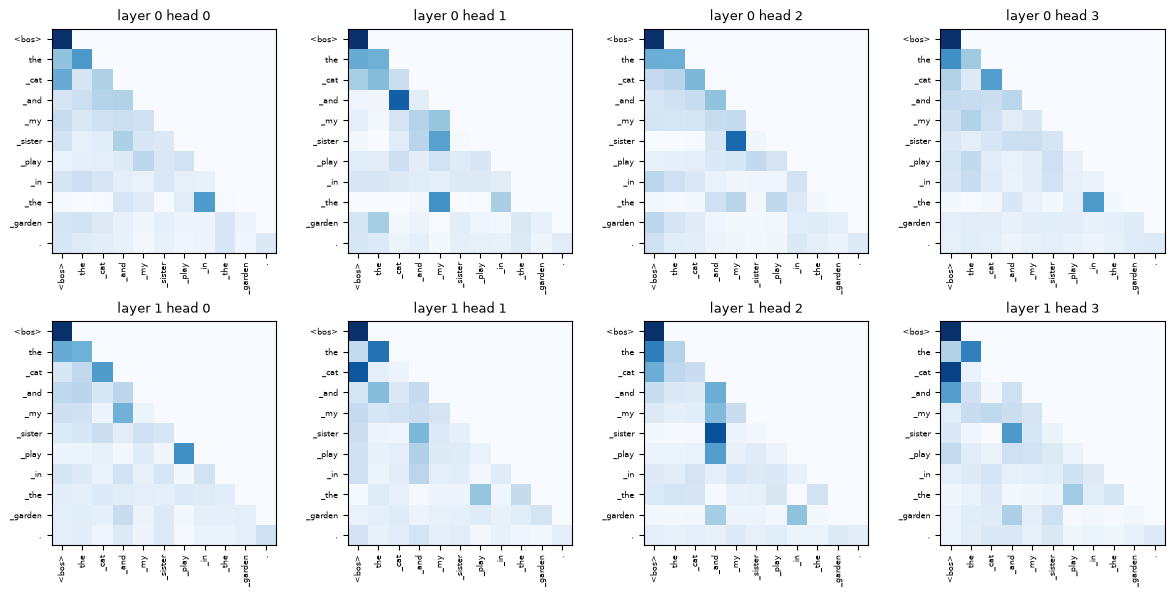

head        prev-token score  first-token score
L0 H0                   0.23               0.21
L0 H1                   0.34               0.16
L0 H2                   0.27               0.20
L0 H3                   0.24               0.21
L1 H0                   0.20               0.18
L1 H1                   0.12               0.24
L1 H2                   0.20               0.20
L1 H3                   0.13               0.26


In [53]:
sent = "the cat and my sister play in the garden."
ids_s = np.array([tok.encode(sent, bos=True)])
labels_s = [tok.itos[i].replace(" ", "_") for i in ids_s[0]]
_, _, atts, resid = gpt_forward(P, ids_s, CFG)
fig, ax = plt.subplots(CFG["L"], CFG["n_heads"], figsize=(12, 6))
for l in range(CFG["L"]):
    for h in range(CFG["n_heads"]):
        A_ = atts[l][0, h]
        ax[l, h].imshow(A_, cmap="Blues", vmin=0, vmax=1)
        ax[l, h].set_title(f"layer {l} head {h}", fontsize=9)
        ax[l, h].set_xticks(range(len(labels_s))); ax[l, h].set_xticklabels(labels_s, rotation=90, fontsize=6)
        ax[l, h].set_yticks(range(len(labels_s))); ax[l, h].set_yticklabels(labels_s, fontsize=6)
plt.tight_layout(); plt.show()

print(f"{'head':<10}{'prev-token score':>18}{'first-token score':>19}")
for l in range(CFG["L"]):
    for h in range(CFG["n_heads"]):
        A_ = atts[l][0, h]; T_ = A_.shape[0]
        prev = np.mean([A_[i, i - 1] for i in range(1, T_)]); first = A_[1:, 0].mean()
        print(f"L{l} H{h:<6}{prev:>18.2f}{first:>19.2f}")

### 11.2 The logit lens

**What it is.** The residual stream has the same width $d$ at every layer, so we can take the stream **part-way through** the model, apply the final norm and the unembedding, and read off what the model "would predict" if it stopped there (nostalgebraist 2020, "interpreting GPT: the logit lens").

$$\text{logits}^{(\ell)} = \text{LN}_f\big(x^{(\ell)}\big)\,E^\top$$

Watching the prediction sharpen layer by layer shows where in the network the answer forms. After the last layer it is exactly the real output.

In [54]:
targets_s = ids_s[0, 1:]
print(f"{'stream after':<14}{'loss':>7}   top-1 prediction at each position")
for l, xr in enumerate(resid):
    lens_logits = layer_norm(xr, P["lnf_g"], P["lnf_b"]) @ P["tok_emb"].T        # (1, T, V)
    loss_l = cross_entropy_np(lens_logits[0, :-1], targets_s)
    preds = [tok.itos[i] for i in lens_logits[0].argmax(-1)]
    name = "embeddings" if l == 0 else f"block {l - 1}"
    print(f"{name:<14}{loss_l:>7.3f}   {preds}")
print(f"{'(actual next)':<21}   {[tok.itos[i] for i in targets_s]}")

stream after     loss   top-1 prediction at each position
embeddings     10.731   ['<bos>', 'the', ' dog', ' and', ' my', ' sister', ' play', ' in', ' the', ' garden', '.']
block 0         1.228   ['the', ' old', ' play', ' my', ' sister', ' old', ' on', ' the', ' garden', ' garden', '<eos>']
block 1         0.840   ['the', ' teacher', ' is', ' the', ' sister', ' sit', ' in', ' the', ' garden', '.', '<eos>']
(actual next)           ['the', ' cat', ' and', ' my', ' sister', ' play', ' in', ' the', ' garden', '.']


How to read it: the "embeddings" row predicts each **current** token again (with tied embeddings, $E[x]\cdot E[x]$ is the largest score), so its loss is very high. After block 0 most of the work is already done, and block 1 refines it. Mistakes such as " teacher" instead of " cat" are not really errors: after "the", several animals and people are equally valid in our toy language.

For a guided tour of how researchers take these ideas much further (circuits, induction heads, superposition), read Anthropic's "A Mathematical Framework for Transformer Circuits" in the further reading list.

## Recap: formula cheat sheet

| Step | Formula | Shape |
|---|---|---|
| embedding | $x = E[\text{ids}] + P[\text{pos}]$ | $(B,T) \to (B,T,d)$ |
| RoPE | rotate pair $i$ of $q, k$ by $m\theta_i$, $\theta_i = \text{base}^{-2i/d}$ | unchanged |
| projections | $Q = XW_Q,\; K = XW_K,\; V = XW_V$, split into heads | $(B,h,T,d_{head})$ |
| attention | $\text{softmax}\big(QK^\top/\sqrt{d_{head}} + M\big)V$ | scores $(B,h,T,T)$ |
| merge + output | $\text{concat}(\text{heads})\,W_O$ | $(B,T,d)$ |
| block | $x \mathrel{+}= \text{Attn}(\text{LN}(x));\; x \mathrel{+}= \text{FFN}(\text{LN}(x))$ | $(B,T,d)$ |
| FFN (GELU / SwiGLU) | $\text{GELU}(xW_1)W_2$ / $(\text{SiLU}(xW_1)\odot xW_3)W_2$ | hidden $4d$ / $\tfrac{8}{3}d$ |
| logits | $\text{LN}_f(x)\,E^\top$ | $(B,T,V)$ |
| loss | $-\tfrac{1}{T}\sum_t \log p(x_{t+1}\mid x_{\le t})$, perplexity $= e^{\mathcal L}$ | scalar |
| parameters | $\approx Vd + 12Ld^2$ | |
| FLOPs | forward $\approx 2N$ per token; training $\approx 6ND$ | |
| KV cache | $2 \cdot L \cdot n_{kv} \cdot d_{head} \cdot T \cdot B \cdot$ bytes | |
| Chinchilla | $D \approx 20N$ (rule of thumb) | |
| LoRA | $W + \tfrac{\alpha}{r}BA$, trainable $r(d+k)$ | |
| int-$b$ symmetric | $s = \max|w|/(2^{b-1}-1)$, $\hat w = s\cdot\text{round}(w/s)$ | |
| DPO | $-\log\sigma\big(\beta[\Delta_w - \Delta_l]\big)$, $\Delta = \log\pi_\theta - \log\pi_{ref}$ | |
| MoE balance | $E\sum_i f_i P_i$ | |

**The shape letters:**

| Symbol | Meaning | Our toy | A typical 7B-class model (illustrative) |
|---|---|---|---|
| $B$ | batch size (sequences processed together) | 32 in training | varies |
| $T$ | sequence length (tokens) | up to 64 | thousands to over 100k |
| $d$ ($d_{model}$) | model width | 64 | 4096 |
| $h$ | attention heads | 4 | 32 |
| $d_{head}$ | width of one head, $d/h$ | 16 | 128 |
| $L$ | number of blocks | 2 | 32 |
| $V$ | vocabulary size | about 150 (printed in section 1.2) | 32k-150k+ |

## Interview questions

1. **Why divide attention scores by $\sqrt{d_k}$?** Dot products of random vectors have variance $d_k$; without scaling, softmax saturates into near one-hot weights with vanishing gradients. Dividing by $\sqrt{d_k}$ brings the variance back to about 1.
2. **What does the causal mask do and why is it needed?** It sets scores for future positions to $-\infty$ so each token only attends to itself and earlier tokens. Without it, next-token training would be trivial (the answer is visible) and generation would not match training.
3. **Why does RoPE encode relative position?** Rotations compose: $R(m)^\top R(n) = R(n-m)$, so the score between a rotated query and key depends only on $n - m$.
4. **Roughly how many parameters does a transformer with $L$ layers and width $d$ have?** About $12Ld^2$ in the blocks ($4d^2$ attention + $8d^2$ FFN) plus $Vd$ for the (tied) embeddings.
5. **What is the KV cache and what does it cost?** Stored keys and values of past tokens so each new token needs only one forward step. Memory $= 2 L n_{kv} d_{head} T B \times$ bytes, which is why GQA/MQA, quantised caches and paging exist.
6. **Prefill vs decode?** Prefill processes the whole prompt in parallel (compute-bound, sets time to first token). Decode makes one token per step (memory-bound, sets inter-token latency).
7. **How do you estimate the compute to train a model?** $C \approx 6ND$ FLOPs ($2N$ forward + $4N$ backward per token). Chinchilla suggests $D \approx 20N$ for compute-optimal training.
8. **Why is training memory about 16 bytes per parameter but inference about 2?** Training holds bf16 weights and gradients, an fp32 master copy and two fp32 Adam moments; inference holds only the weights (plus the KV cache).
9. **How does FlashAttention get the exact same result while using less memory?** It processes keys in tiles with an online softmax (running max, running sum, rescaling), so the $T\times T$ matrix is never stored.
10. **Why does LoRA initialise $B$ to zero?** So $BA = 0$ and the adapted model starts identical to the pre-trained one; training then learns only the low-rank change.
11. **What does loss masking do in SFT?** It excludes prompt (user/system) tokens from the loss so the model learns to produce answers, not to imitate questions.
12. **Encoder-only vs decoder-only?** Encoders see the whole input (bidirectional, masked-LM training) and are best for understanding and embeddings; decoders are causal and trained on next-token prediction, which is what generation needs.

## Further reading

- Vaswani et al. 2017, **"Attention Is All You Need"** (arXiv:1706.03762): the original transformer.
- Jay Alammar, **"The Illustrated Transformer"** (https://jalammar.github.io/illustrated-transformer/): the classic visual walk-through.
- Andrej Karpathy, **nanoGPT** (https://github.com/karpathy/nanoGPT) and the video **"Let's build GPT: from scratch, in code, spelled out"**: the clearest code-first build of a GPT.
- Sennrich et al. 2016, **"Neural Machine Translation of Rare Words with Subword Units"** (arXiv:1508.07909): BPE for NLP.
- Su et al. 2021, **"RoFormer: Enhanced Transformer with Rotary Position Embedding"** (arXiv:2104.09864): RoPE.
- Press et al. 2021, **"Train Short, Test Long"** (arXiv:2108.12409): ALiBi. Chen et al. 2023, **"Extending Context Window of Large Language Models via Positional Interpolation"** (arXiv:2306.15595). Peng et al. 2023, **"YaRN"** (arXiv:2309.00071).
- Ainslie et al. 2023, **"GQA: Training Generalized Multi-Query Transformer Models from Multi-Head Checkpoints"** (arXiv:2305.13245).
- Milakov and Gimelshein 2018, **"Online normalizer calculation for softmax"** (arXiv:1805.02867); Dao et al. 2022, **"FlashAttention"** (arXiv:2205.14135).
- Zhang and Sennrich 2019, **"Root Mean Square Layer Normalization"** (arXiv:1910.07467); Shazeer 2020, **"GLU Variants Improve Transformer"** (arXiv:2002.05202).
- Kaplan et al. 2020, **"Scaling Laws for Neural Language Models"** (arXiv:2001.08361); Hoffmann et al. 2022, **"Training Compute-Optimal Large Language Models"** (Chinchilla, arXiv:2203.15556).
- Hu et al. 2021, **"LoRA: Low-Rank Adaptation of Large Language Models"** (arXiv:2106.09685).
- Dettmers et al. 2022, **"LLM.int8()"** (arXiv:2208.07339); Frantar et al. 2022, **"GPTQ"** (arXiv:2210.17323).
- Ouyang et al. 2022, **"Training language models to follow instructions with human feedback"** (InstructGPT, arXiv:2203.02155); Rafailov et al. 2023, **"Direct Preference Optimization"** (arXiv:2305.18290).
- Fedus et al. 2021, **"Switch Transformers"** (arXiv:2101.03961); Gu and Dao 2023, **"Mamba"** (arXiv:2312.00752).
- Devlin et al. 2018, **"BERT"** (arXiv:1810.04805); Raffel et al. 2019, **"Exploring the Limits of Transfer Learning with a Unified Text-to-Text Transformer"** (T5, arXiv:1910.10683).
- Elhage et al. 2021 (Anthropic), **"A Mathematical Framework for Transformer Circuits"** (https://transformer-circuits.pub/2021/framework/index.html); nostalgebraist 2020, **"interpreting GPT: the logit lens"** (LessWrong).

**Where to go next in this repo:** [23_llm_caching_kv_cache_prompt_semantic_cag](23_llm_caching_kv_cache_prompt_semantic_cag.ipynb) (caching in production), [24_how_llms_differ_from_each_other](24_how_llms_differ_from_each_other.ipynb) (how real models differ), [21_fine_tuning_hands_on_cpu](21_fine_tuning_hands_on_cpu.ipynb) (post-training by hand).

In [55]:
print(f"notebook finished in {time.time() - NB_START:.0f} s")

notebook finished in 16 s
